> **Data preparation moved upstream.** Sections 2-4 used to load raw DHS/MICS files
> and derive the FGM event fields directly here. That now happens once in
> `00_EDA_DHS_Country_Year.ipynb`, which resolves the country's DHS variable codes,
> auto-discovers every survey round, runs a data quality pass, and writes a cleaned,
> harmonized `<ISO3>_fgm_events.rds` this notebook reads. Run that notebook first for a
> country, and again whenever its raw data changes or a new round is added.

# FGM Attitudinal Risk Incidence, a country adjustable pipeline

Important, read before using this notebook. Unlike FGM risk incidence, no
methodology for attitudinal risk incidence was found anywhere in the UNFPA
materials reviewed for this project, including the Annual Technical
Consultation slide deck the risk incidence work is based on. This notebook
implements the best evidence default proposed in section 5 of
00_Methodology/01_Improved_Risk_Incidence_Methodology.md, a multilevel
regression of stated attitude on individual and community covariates,
following the approach used in a 2023 pooled 14 country DHS study, combined
with the same spatial small area smoothing backbone used for risk incidence
in the companion notebook.

This is a proposed default, not a confirmed UNFPA method. Confirm the
intended definition of attitudinal risk incidence with Dr Wisal Ahmed or
Romesh Silva before treating any output from this notebook as final.

Sections
0. Configuration (edit this per country)
1. Setup and packages
2. Load DHS and MICS attitude data
3. Clean and harmonize data
4. Define the attitude outcome
5. Descriptive summary
6. Multilevel logistic model, individual and community covariates
7. Subnational small area estimation for attitude
8. Attitude maps
9. Trend over time and change point
10. Model validation
11. Optional machine learning cross check
12. Final outputs

## 0. Configuration, edit this block for each country run

This is the only section that should normally change between countries. Every later section reads from these settings rather than hard coding a country name or file path.

In [1]:
# Country identity
country_name   <- "Kenya"
country_iso3   <- "KEN"       # ISO3 code; matches 00_EDA_DHS_Country_Year_v2.ipynb
survey_year    <- 2022

proc_data_dir     <- file.path("..", "02_Data", "processed", country_iso3)
combined_data_dir <- file.path(proc_data_dir, "combined")
output_dir        <- file.path("..", "03_Outputs", country_iso3)

dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)


admin_level          <- "admin1"
shapefile_path        <- file.path("..", "02_Data", "raw", as.character(survey_year), "Survey",
                                     "boundaries", "Kenya Boundaries", "shps",
                                     "sdr_subnational_boundaries.shp")
region_var_shapefile  <- "DHSREGEN"  # Kenya DHS county-name field
standardize_region <- function(x) {
  x |> as.character() |> toupper() |>
    stringr::str_replace_all("[^A-Z ]", " ") |> stringr::str_squish()
}

# Age window and toggles
max_age_years <- 49   

run_spatial_model  <- file.exists(shapefile_path)   # TRUE automatically once the boundary above exists
run_change_point   <- TRUE
run_ml_crosscheck  <- TRUE

cat("Configured for:", country_name, paste0("(", country_iso3, ")"), "\n")
if (!run_spatial_model) {
  message("No admin1 boundary shapefile found at ", shapefile_path,
          ", spatial modeling (sections 11-12) will be skipped for this run.")
}

Configured for: Kenya (KEN) 


## 1. Setup and packages

In [2]:
required_packages <- c(
  "tidyverse", "survey", "survival", "survminer",
  "sf", "spdep", "INLA", "SUMMER", "mgcv", "changepoint", "randomForestSRC"
)

missing_packages <- required_packages[!vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing_packages) > 0) {
  message("Missing packages, install before continuing: ", paste(missing_packages, collapse = ", "))
}

library(tidyverse)
library(survey)
library(survival)
library(survminer)
library(sf)
library(spdep)
library(mgcv)

# INLA and SUMMER are loaded lazily inside section 11 so the earlier sections
# still run on a machine where the spatial packages are not yet installed.

# A region can be left with only one sampled cluster once a domain estimate subsets the
# data (section 10), or once rounds are combined and a stratum happens to have a single
# PSU. "adjust" recenters that lonely PSU to the overall stratum mean instead of
# erroring, the standard remedy documented in ?survey::svydesign.
options(survey.lonely.psu = "adjust")

set.seed(20260101)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Loading required package: grid



Loading required package: Matrix




Attaching package: ‘Matrix’




...

To access larger datasets in this package, install the spDataLarge
package with: `install.packages('spDataLarge',
repos='https://nowosad.github.io/drat/', type='source')`



Loading required package: nlme




Attaching package: ‘nlme’




The following object is masked from ‘package:dplyr’:

    collapse




This is mgcv 1.9-4. For overview type '?mgcv'.



## 2. Load prepared data

Reads the cleaned, harmonized, multi-round file `00_EDA_DHS_Country_Year.ipynb` wrote for
this country. That notebook is what actually resolves the country's DHS variable codes
(including catching mismapped ones, e.g. this notebook previously pointed its age-at-cutting
field at the wrong DHS variable), runs the data quality checks, and derives `fgm_event`,
`time`, and `birth_cohort`. First 5 rows are printed below so you can see the incoming
data before anything else runs.

In [3]:
fgm_events_path <- file.path(combined_data_dir, paste0(country_iso3, "_fgm_events.rds"))
if (!file.exists(fgm_events_path)) {
  stop("No prepared data found at ", fgm_events_path,
       ". Run 00_EDA_DHS_Country_Year.ipynb for this country first.")
}

fgm_events <- readRDS(fgm_events_path) |>
  dplyr::filter(time <= max_age_years) |>
  dplyr::mutate(
    # Match the region-name convention expected by the existing spatial code.
    region = toupper(region),
    # Match the cohort-label convention used throughout the existing pipeline.
    birth_cohort = stringr::str_replace(
      birth_cohort, "^(\\d{4})-(\\d{4})$", "\\1 to \\2"
    ),
    birth_cohort = factor(birth_cohort, levels = sort(unique(birth_cohort)))
  )

# Audit logically impossible daughter histories before excluding them.
invalid_daughter_events <- fgm_events |>
  dplyr::filter(
    record_type == "daughter", fgm_event == 1,
    !is.na(time), !is.na(age), time > age
  )
cat("Daughter histories excluded because FGM age exceeds current age:",
    nrow(invalid_daughter_events), "\n")

fgm_events <- fgm_events |>
  dplyr::filter(!(record_type == "daughter" & fgm_event == 1 & time > age))

cat("Rows loaded:", nrow(fgm_events), "respondents,",
    dplyr::n_distinct(fgm_events$survey_year), "survey round(s):",
    paste(sort(unique(fgm_events$survey_year)), collapse = ", "), "\n\n")

head(fgm_events, 5)

Daughter histories excluded because FGM age exceeds current age: 0 


Rows loaded: 31361 respondents, 1 survey round(s): 2022 



id,record_type,survey_type,survey_year,country,region,cluster,urban_rural,weight,psu,strata,lat,lon,missing_gps,age,birth_year,birth_cohort,ethnicity,fgm_event,time
<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<fct>,<chr>,<int>,<dbl>
2022-1-4-2,self,DHS,2022,KEN,MOMBASA,1,urban,1.296049,1,1,NA,NA,NA,34,1987,1985 to 1989,somali,1,9
2022-1-10-1,self,DHS,2022,KEN,MOMBASA,1,urban,1.296049,1,1,NA,NA,NA,33,1989,1985 to 1989,kikuyu,0,33
2022-1-13-2,self,DHS,2022,KEN,MOMBASA,1,urban,1.296049,1,1,NA,NA,NA,39,1982,1980 to 1984,kamba,0,39
2022-1-20-2,self,DHS,2022,KEN,MOMBASA,1,urban,1.296049,1,1,NA,NA,NA,30,1992,1990 to 1994,other,0,30
2022-1-26-2,self,DHS,2022,KEN,MOMBASA,1,urban,1.296049,1,1,NA,NA,NA,28,1993,1990 to 1994,kamba,0,28


## 3. Data quality, already handled upstream

`00_EDA_DHS_Country_Year.ipynb` already flags and removes rows with missing status,
missing age at cutting for a respondent recorded as cut, implausible ages, missing
region, and missing weight, and de-duplicates by id, before writing the file loaded
above. This section is just a shape check before modeling.

In [4]:
dplyr::count(fgm_events, survey_year, fgm_event)
dplyr::glimpse(fgm_events)

survey_year,fgm_event,n
<int>,<int>,<int>
2022,0,26476
2022,1,4885


Rows: 31,361
Columns: 20
$ id           <chr> "2022-1-4-2", "2022-1-10-1", "2022-1-13-2", "2022-1-20-2"…
$ record_type  <chr> "self", "self", "self", "self", "self", "self", "self", "…
$ survey_type  <chr> "DHS", "DHS", "DHS", "DHS", "DHS", "DHS", "DHS", "DHS", "…
$ survey_year  <int> 2022, 2022, 2022, 2022, 2022, 2022, 2022, 2022, 2022, 202…
$ country      <chr> "KEN", "KEN", "KEN", "KEN", "KEN", "KEN", "KEN", "KEN", "…
$ region       <chr> "MOMBASA", "MOMBASA", "MOMBASA", "MOMBASA", "MOMBASA", "M…
$ cluster      <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 3, 3, …
$ urban_rural  <chr> "urban", "urban", "urban", "urban", "urban", "urban", "ur…
$ weight       <dbl> 1.296049, 1.296049, 1.296049, 1.296049, 1.296049, 1.29604…
$ psu          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 3, 3, …
$ strata       <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, …
$ lat          <dbl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, N…
$ lon          

## 4. The FGM event

Each respondent is already a time to event record: `fgm_event` is 1 if she was cut and
`time` is her age at cutting, or `fgm_event` is 0 and `time` is her age at interview,
censored at `max_age_years`, if she had not been cut by the time of the survey. Birth
cohort was reconstructed from `birth_year` (the survey's own respondent year of birth
variable), giving decades of retrospective cohort coverage from a single cross sectional
survey, the same device the original UNFPA analysis relies on.

In [5]:
dplyr::count(fgm_events, fgm_event)

fgm_event,n
<int>,<int>
0,26476
1,4885


## 5. Create person time data

Expand each respondent into one row per completed year of life up to her event or censoring age, the format a discrete time hazard model in section 8 requires. This mirrors the person month construction used by the SUMMER package for under five mortality, applied here to age at cutting instead of age at death.

In [6]:
make_person_time <- function(df) {
  df |>
    dplyr::mutate(row_id = dplyr::row_number()) |>
    dplyr::rowwise() |>
    dplyr::reframe(
      row_id, id, survey_type, survey_year, country, region, cluster, urban_rural, weight,
      birth_cohort, ethnicity, record_type,
      age_year = 0:floor(time),
      event = dplyr::if_else(age_year == floor(time) & fgm_event == 1, 1L, 0L)
    ) |>
    dplyr::ungroup()
}

person_time <- make_person_time(fgm_events)
readr::write_csv(person_time, file.path(proc_data_dir, paste0(country_iso3, "_person_time.csv")))
cat("Person time rows:", nrow(person_time), "from", dplyr::n_distinct(person_time$id), "respondents\n")

Person time rows: 547986 from 31361 respondents


## 6. Kaplan Meier baseline

Reproduce the original UNFPA approach first, before moving to the formal hazard model, so the two can be compared directly in section 15.

In [7]:
# km_fit <- survival::survfit(
#   survival::Surv(time, fgm_event) ~ birth_cohort,
#   data = fgm_events
# )

# survminer::ggsurvplot(
#   km_fit,
#   data = fgm_events,
#   xlab = "Age of girl or woman",
#   ylab = "Probability of not experiencing FGM",
#   legend.title = "Birth cohort",
#   ggtheme = ggplot2::theme_minimal()
# )

In [8]:
fgm_events_self_plot     <- fgm_events |> dplyr::filter(record_type == "self")     |> dplyr::mutate(birth_cohort = droplevels(birth_cohort))
fgm_events_daughter_plot <- fgm_events |> dplyr::filter(record_type == "daughter") |> dplyr::mutate(birth_cohort = droplevels(birth_cohort))


In [9]:
fgm_events <- readRDS(fgm_events_path) |>
  dplyr::filter(time <= max_age_years) |>
  dplyr::mutate(
    birth_cohort = factor(
      birth_cohort,
      levels = sort(unique(birth_cohort))
    )
  )

In [10]:
class(fgm_events$birth_cohort)
levels(fgm_events$birth_cohort)
table(fgm_events$record_type)

[1] "factor"

[1] "1970 to 1974" "1975 to 1979" "1980 to 1984" "1985 to 1989" "1990 to 1994"
 [6] "1995 to 1999" "2000 to 2004" "2005 to 2009" "2010 to 2014" "2015 to 2019"
[11] "2020 to 2024"


daughter     self 
   14541    16820 

In [11]:
fgm_events_self_plot     <- fgm_events |> dplyr::filter(record_type == "self")     |> dplyr::mutate(birth_cohort = droplevels(birth_cohort))
fgm_events_daughter_plot <- fgm_events |> dplyr::filter(record_type == "daughter") |> dplyr::mutate(birth_cohort = droplevels(birth_cohort))


Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


Warning message in margin(top = 18):
“`...` must be empty.
✖ Problematic argument:
• top = 18”


Warning message in margin(right = 25):
“`...` must be empty.
✖ Problematic argument:
• right = 25”


Warning message in margin(top = 12):
“`...` must be empty.
✖ Problematic argument:
• top = 12”


...

Warning message in margin(right = 25):
“`...` must be empty.
✖ Problematic argument:
• right = 25”


Warning message in margin(top = 12):
“`...` must be empty.
✖ Problematic argument:
• top = 12”


Warning message in margin(top = 10, bottom = 10):
“`...` must be empty.
✖ Problematic arguments:
• top = 10
• bottom = 10”


Warning message in margin(bottom = 25):
“`...` must be empty.
✖ Problematic argument:
• bottom = 25”


Warning message in margin(top = 35, right = 30, bottom = 30, left = 25):
“`...` must be empty.
✖ Problematic arguments:
• top = 35
• right = 30
• bottom = 30
• left = 25”


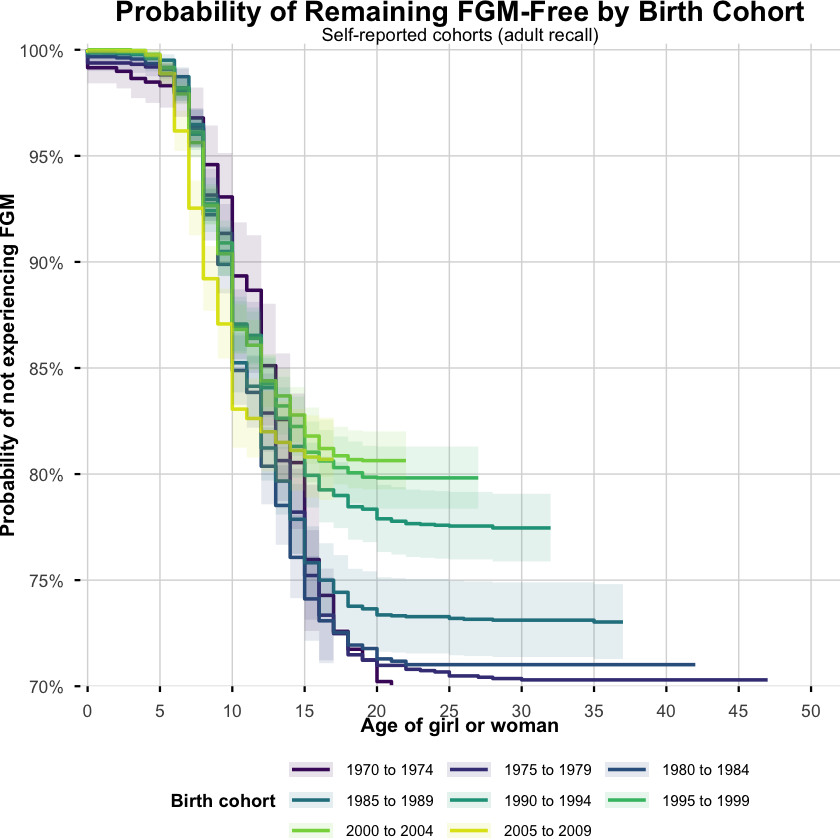

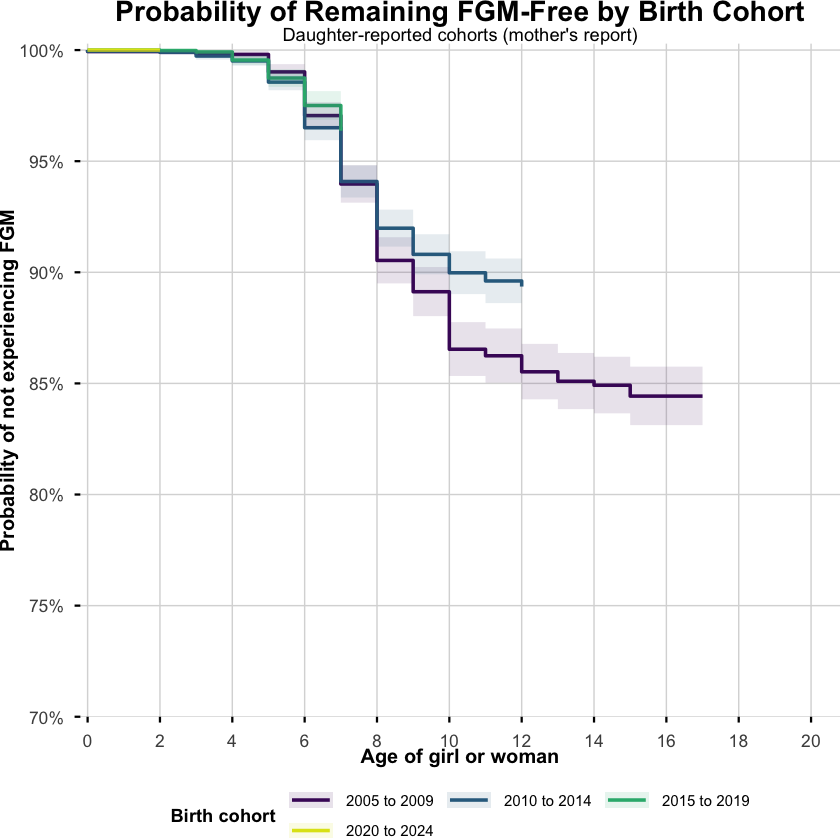

In [12]:
fgm_events_self_plot     <- fgm_events |> dplyr::filter(record_type == "self")     |> dplyr::mutate(birth_cohort = droplevels(birth_cohort))
fgm_events_daughter_plot <- fgm_events |> dplyr::filter(record_type == "daughter") |> dplyr::mutate(birth_cohort = droplevels(birth_cohort))

build_km_plot <- function(plot_data, subtitle_label, xlim_max, break_by, file_suffix) {
  km_fit <- survival::survfit(survival::Surv(time, fgm_event) ~ birth_cohort, data = plot_data)
  n_cohorts <- nlevels(plot_data$birth_cohort)

  km_plot <- survminer::ggsurvplot(
    km_fit, data = plot_data,
    conf.int = TRUE, conf.int.alpha = 0.12, censor = FALSE,
    xlab = "Age of girl or woman", ylab = "Probability of not experiencing FGM",
    xlim = c(0, xlim_max), ylim = c(0.70, 1.00), break.time.by = break_by,
    legend.title = "Birth cohort", legend = "bottom",
    legend.labs = levels(plot_data$birth_cohort), ncol = 3,
    palette = viridisLite::viridis(n = n_cohorts, option = "D", begin = 0.05, end = 0.95),
    ggtheme = theme_minimal(base_size = 14)
  )

  # Mark exactly where each cohort's curve stops early because it hasn't been
  # followed any further -- without this, a short curve (e.g. a cohort only
  # observed to age 4) just trails off and is easy to mistake for missing data.
  end_points <- plot_data |>
    dplyr::group_by(birth_cohort) |>
    dplyr::summarise(max_age = max(time, na.rm = TRUE), .groups = "drop") |>
    dplyr::filter(max_age < xlim_max) |>
    dplyr::left_join(
      broom::tidy(km_fit) |>
        dplyr::mutate(birth_cohort = stringr::str_remove(strata, "^birth_cohort=")) |>
        dplyr::group_by(birth_cohort) |>
        dplyr::filter(time == max(time)) |>
        dplyr::select(birth_cohort, estimate),
      by = "birth_cohort"
    )

  km_plot$plot <- km_plot$plot +
    # ggplot2::geom_point(
    #   data = end_points,
    #   ggplot2::aes(x = max_age, y = estimate, color = birth_cohort),
    #   shape = 1, size = 3, stroke = 1.2, show.legend = FALSE
    # ) +
    # ggrepel::geom_text_repel(
    #   data = end_points,
    #   ggplot2::aes(x = max_age, y = estimate, label = paste0("to age ", max_age)),
    #   size = 3, color = "grey30", min.segment.length = 0, seed = 1
    # ) +
    labs(
      title = "Probability of Remaining FGM-Free by Birth Cohort",
      subtitle = paste0(subtitle_label, "")
    ) +
    scale_x_continuous(breaks = seq(0, xlim_max, by = break_by), limits = c(0, xlim_max),
                        expand = expansion(mult = c(0.01, 0.04))) +
    scale_y_continuous(breaks = seq(0.70, 1.00, by = 0.05), limits = c(0.70, 1.00),
                        labels = scales::percent_format(accuracy = 1),
                        expand = expansion(mult = c(0, 0.01))) +
    theme(
      plot.title = element_text(face = "bold", size = 17, hjust = 0.5, margin = margin(top = 10, bottom = 10)),
      plot.subtitle = element_text(size = 11, hjust = 0.5, lineheight = 1.15, margin = margin(bottom = 25)),
      axis.title.x = element_text(face = "bold", size = 12, margin = margin(top = 18)),
      axis.title.y = element_text(face = "bold", size = 12, margin = margin(right = 25)),
      axis.text.x = element_text(size = 10.5, angle = 0, hjust = 0.5, vjust = 0.5),
      axis.text.y = element_text(size = 10.5),
      legend.position = "bottom", legend.direction = "horizontal", legend.box = "vertical",
      legend.justification = "center",
      legend.title = element_text(face = "bold", size = 11),
      legend.text = element_text(size = 9),
      legend.key.width = unit(1.0, "cm"), legend.key.height = unit(0.4, "cm"),
      legend.spacing.x = unit(0.10, "cm"), legend.margin = margin(top = 12),
      panel.grid.major.x = element_line(colour = "grey85", linewidth = 0.4),
      panel.grid.major.y = element_line(colour = "grey85", linewidth = 0.4),
      panel.grid.minor = element_blank(),
      plot.margin = margin(top = 35, right = 30, bottom = 30, left = 25)
    ) +
    guides(colour = guide_legend(ncol = 3, byrow = TRUE), fill = guide_legend(ncol = 3, byrow = TRUE))

  print(km_plot)
  ggsave(filename = paste0("FGM_Kaplan_Meier_", file_suffix, ".png"), plot = km_plot$plot,
         width = 17, height = 14, units = "in", dpi = 300, bg = "white")
  ggsave(filename = paste0("FGM_Kaplan_Meier_", file_suffix, ".pdf"), plot = km_plot$plot,
         width = 17, height = 14, units = "in", device = cairo_pdf, bg = "white")
  km_fit
}

km_fit_self <- build_km_plot(
  fgm_events_self_plot,
  "Self-reported cohorts (adult recall)",
  50, 5, "self"
)
km_fit_daughter <- build_km_plot(
  fgm_events_daughter_plot,
  "Daughter-reported cohorts (mother's report)",
  20, 2, "daughter"
)


## 7. Estimate FGM incidence risk

Convert the Kaplan Meier survival probability into a cumulative risk table at a set of reference ages

In [13]:
# reference_ages <- c(1, 2, 5, 8, 10, 15, 18)
# #reference_ages <- seq(1, 50, by = 1)

# risk_table <- summary(km_fit, times = reference_ages, extend = TRUE)

# risk_by_age <- tibble::tibble(
#   birth_cohort = risk_table$strata,
#   age          = risk_table$time,
#   survival     = risk_table$surv,
#   fgm_risk     = 1 - risk_table$surv,
#   lower_ci     = 1 - risk_table$upper,
#   upper_ci     = 1 - risk_table$lower
# )

# readr::write_csv(risk_by_age, file.path(output_dir, paste0(country_iso3, "_km_risk_by_age.csv")))
# #risk_by_age

In [14]:
reference_ages <- c(1, 2, 5, 8, 10, 15, 18)

build_risk_table <- function(km_fit, record_type_label) {
  risk_table <- summary(km_fit, times = reference_ages, extend = TRUE)
  tibble::tibble(
    #birth_cohort = risk_table$strata,
    birth_cohort = stringr::str_remove(as.character(risk_table$strata), "^birth_cohort="),
    age          = risk_table$time,
    survival     = risk_table$surv,
    fgm_risk     = 1 - risk_table$surv,
    lower_ci     = 1 - risk_table$upper,
    upper_ci     = 1 - risk_table$lower,
    record_type  = record_type_label
  )
}

risk_by_age <- dplyr::bind_rows(
  build_risk_table(km_fit_self, "self"),
  build_risk_table(km_fit_daughter, "daughter")
)

readr::write_csv(risk_by_age, file.path(output_dir, paste0(country_iso3, "_km_risk_by_age.csv")))
#print(risk_by_age, n = Inf, width = Inf)


In [15]:
display_risk_table <- function(data, record_label) {
  cat("\n=====", record_label, "reported: FGM risk by age and birth cohort =====\n")
  table_to_show <- data |>
    dplyr::arrange(birth_cohort, age) |>
    dplyr::mutate(
      fgm_risk = scales::percent(fgm_risk, accuracy = 0.1),
      lower_ci = scales::percent(lower_ci, accuracy = 0.1),
      upper_ci = scales::percent(upper_ci, accuracy = 0.1)
    ) |>
    dplyr::select(birth_cohort, age, fgm_risk, lower_ci, upper_ci)
  IRdisplay::display(as.data.frame(table_to_show))
}

display_risk_table(risk_by_age |> dplyr::filter(record_type == "self"), "Self")
display_risk_table(risk_by_age |> dplyr::filter(record_type == "daughter"), "Daughter")


birth_cohort,age,fgm_risk,lower_ci,upper_ci
<chr>,<dbl>,<chr>,<chr>,<chr>
1970 to 1974,1,0.8%,0.1%,1.6%
1970 to 1974,2,1.0%,0.2%,1.8%
1970 to 1974,5,1.7%,0.6%,2.7%
1970 to 1974,8,5.4%,3.6%,7.2%
1970 to 1974,10,10.7%,8.1%,13.1%
1970 to 1974,15,24.0%,20.5%,27.4%
1970 to 1974,18,28.3%,24.5%,31.8%
1975 to 1979,1,0.6%,0.2%,1.0%
1975 to 1979,2,0.6%,0.2%,1.0%



===== Self reported: FGM risk by age and birth cohort =====


birth_cohort,age,fgm_risk,lower_ci,upper_ci
<chr>,<dbl>,<chr>,<chr>,<chr>
2005 to 2009,1,0.1%,0.0%,0.2%
2005 to 2009,2,0.1%,0.0%,0.2%
2005 to 2009,5,1.0%,0.6%,1.3%
2005 to 2009,8,9.5%,8.4%,10.5%
2005 to 2009,10,13.5%,12.2%,14.7%
2005 to 2009,15,15.6%,14.2%,16.9%
2005 to 2009,18,15.6%,14.2%,16.9%
2010 to 2014,1,0.0%,0.0%,0.1%
2010 to 2014,2,0.1%,0.0%,0.2%



===== Daughter reported: FGM risk by age and birth cohort =====


Interpret the Kenya Kaplan–Meier estimates from the tables and figures generated above. Compare cohorts only at ages where they have adequate observed follow-up. Daughter estimates for the youngest cohorts are provisional because those cohorts have not completed childhood or adolescence; estimates beyond their observed ages must not be interpreted as completed cumulative risk.

## 8. Discrete time hazard model

Move beyond the descriptive Kaplan Meier curves to a single regression that returns a formally estimated cohort trend with a standard error, covariate effects, and a cluster level frailty term,

Age enters as groups (0–4, 5–9, 10–14, 15+), not as a straight line. A linear age term forces the log-odds of cutting to rise or fall steadily with every year of age. That cannot represent a hazard that peaks in early childhood, one that peaks around puberty, or one that stays flat and then drops away in adulthood. With groups, each band gets its own hazard relative to ages 0–4.


In [16]:
hazard_data <- person_time |>
  dplyr::left_join(
    fgm_events |> dplyr::select(id, survey_type, birth_cohort),
    by = c("id", "survey_type", "birth_cohort")
  ) |>
  dplyr::mutate(
    # Age groups instead of a linear age term, so the hazard can peak at any
    # age and fall afterwards. Reference level: ages 0-4.
    age_group = cut(age_year, breaks = c(0, 5, 10, 15, Inf), right = FALSE,
                    labels = c("0-4", "5-9", "10-14", "15+"))
  )

# Design based discrete time hazard model, no frailty, as a first pass.
hazard_design <- survey::svydesign(
  ids = ~cluster, strata = ~interaction(survey_year, region), weights = ~weight,
  data = hazard_data, nest = TRUE
)

survey_type_term <- if (dplyr::n_distinct(hazard_data$survey_type) > 1) " + survey_type" else ""
record_type_term  <- if (dplyr::n_distinct(hazard_data$record_type) > 1) " + record_type" else ""

hazard_model_design_based <- survey::svyglm(
  as.formula(paste0("event ~ age_group + birth_cohort + urban_rural + region + ethnicity",
                     survey_type_term, record_type_term)),
  design = hazard_design, family = quasibinomial()
)

summary(hazard_model_design_based)

# Frailty extension, an unobserved cluster level random effect capturing
# (Age is this model's time scale, so its baseline hazard is left
# unrestricted by age and needs no age term.)
# unmeasured shared cultural or social exposure, recommended in section 2.1
# on the strength of the Ethiopian frailty comparison study.
hazard_model_frailty <- survival::coxph(
  as.formula(paste0(
    "survival::Surv(age_year, age_year + 1, event) ~ birth_cohort + urban_rural + region + ethnicity",
    survey_type_term, record_type_term, " + survival::frailty(cluster)"
  )),
  data = hazard_data
)

summary(hazard_model_frailty)


Call:
svyglm(formula = as.formula(paste0("event ~ age_group + birth_cohort + urban_rural + region + ethnicity", 
    survey_type_term, record_type_term)), design = hazard_design, 
    family = quasibinomial())

Survey design:
survey::svydesign(ids = ~cluster, strata = ~interaction(survey_year, 
    region), weights = ~weight, data = hazard_data, nest = TRUE)

Coefficients:
                          Estimate Std. Error t value Pr(>|t|)    
(Intercept)               -7.57345    0.34998 -21.640  < 2e-16 ***
age_group5-9               2.89883    0.22135  13.096  < 2e-16 ***
age_group10-14             4.03996    0.24264  16.650  < 2e-16 ***
age_group15+               2.64650    0.25058  10.562  < 2e-16 ***
birth_cohort1975 to 1979  -0.16845    0.14128  -1.192 0.233323    
birth_cohort1980 to 1984  -0.33832    0.13575  -2.492 0.012798 *  
birth_cohort1985 to 1989  -0.56532    0.13538  -4.176 3.13e-05 ***
birth_cohort1990 to 1994  -0.84847    0.13624  -6.228 6.05e-10 ***
birth_cohort1995 to 

Warning message in coxpenal.fit(X, Y, istrat, offset, init = init, control, weights = weights, :
“Inner loop failed to coverge for iterations 2 3”


Call:
survival::coxph(formula = as.formula(paste0("survival::Surv(age_year, age_year + 1, event) ~ birth_cohort + urban_rural + region + ethnicity", 
    survey_type_term, record_type_term, " + survival::frailty(cluster)")), 
    data = hazard_data)

  n= 547986, number of events= 4885 

                         coef      se(coef) se2     Chisq   DF    p      
birth_cohort1975 to 1979 -0.155352 0.09576  0.09369    2.63   1.0 1.0e-01
birth_cohort1980 to 1984 -0.356067 0.09447  0.09240   14.21   1.0 1.6e-04
birth_cohort1985 to 1989 -0.471469 0.09224  0.09023   26.13   1.0 3.2e-07
birth_cohort1990 to 1994 -0.660846 0.09307  0.09103   50.41   1.0 1.2e-12
birth_cohort1995 to 1999 -0.794399 0.09329  0.09122   72.51   1.0 1.7e-17
birth_cohort2000 to 2004 -0.945137 0.09247  0.09053  104.48   1.0 1.6e-24
birth_cohort2005 to 2009 -1.056189 0.10209  0.10020  107.03   1.0 4.4e-25
birth_cohort2010 to 2014 -1.121687 0.12397  0.12230   81.86   1.0 1.5e-19
birth_cohort2015 to 2019 -1.074459 0.16734  0

## 9. Cohort and trend smoothing

Replace a low flexibility parametric cohort effect with a Bayesian penalized spline, the same smoothing device UN IGME uses in its Bayesian B spline bias reduction model for under five mortality, to avoid both overfitting single year cohorts and underfitting a genuinely nonlinear decline.

In [17]:
# cohort_numeric <- hazard_data |>
#   dplyr::mutate(cohort_mid = as.numeric(stringr::str_extract(birth_cohort, "^[0-9]+")) + 2)

# trend_model <- mgcv::gam(
#   event ~ s(cohort_mid, bs = "ps", k = 10) + s(age_year, bs = "ps", k = 10) +
#     urban_rural + region,
#   family = binomial(),
#   weights = weight,
#   data = cohort_numeric
# )

# summary(trend_model)
# plot(trend_model, pages = 1, shade = TRUE)

Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


...

Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”


Warning message in eval(family$initialize):
“non-integer #successes in a binomial glm!”



Family: binomial 
Link function: logit 

Formula:
event ~ s(cohort_mid, bs = "ps", k = 10) + s(age_year, bs = "ps", 
    k = 10) + urban_rural + region + record_type

Parametric coefficients:
                       Estimate Std. Error z value Pr(>|z|)    
(Intercept)           -8.409517   1.335813  -6.295 3.07e-10 ***
urban_ruralurban      -0.701817   0.056739 -12.369  < 2e-16 ***
regionBOMET            0.033220   0.196803   0.169 0.865954    
regionBUNGOMA         -1.998917   0.282702  -7.071 1.54e-12 ***
regionBUSIA           -5.902123   2.182454  -2.704 0.006844 ** 
regionELGEYO MARAKWET -0.059902   0.261114  -0.229 0.818550    
regionEMBU            -0.191918   0.235044  -0.817 0.414205    
regionGARISSA          3.371367   0.180945  18.632  < 2e-16 ***
regionHOMA BAY        -2.128257   0.363234  -5.859 4.65e-09 ***
regionISIOLO           2.380781   0.210609  11.304  < 2e-16 ***
regionKAJIADO          0.574855   0.187911   3.059 0.002219 ** 
regionKAKAMEGA        -4.200628   0.669

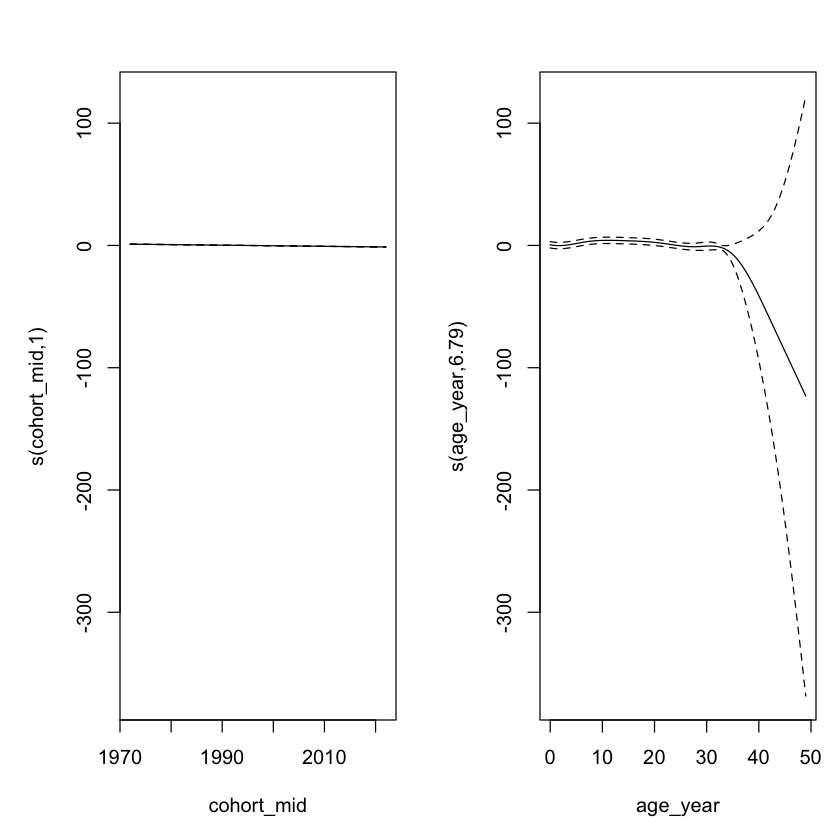

In [18]:
cohort_numeric <- hazard_data |>
  dplyr::mutate(
    cohort_mid  = as.numeric(stringr::str_extract(birth_cohort, "^[0-9]+")) + 2,
    record_type = factor(record_type)
  )

trend_model <- mgcv::gam(
  event ~ s(cohort_mid, bs = "ps", k = 10) + s(age_year, bs = "ps", k = 10) +
    urban_rural + region + record_type,
  family = binomial(),
  weights = weight,
  data = cohort_numeric
)

summary(trend_model)
plot(trend_model, pages = 1, shade = TRUE)


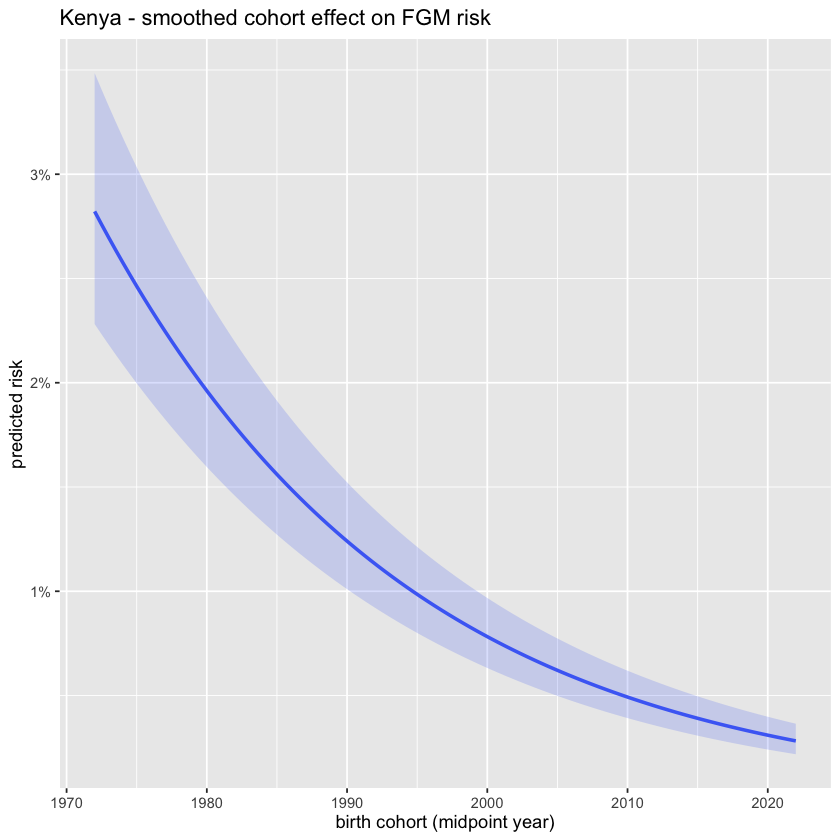

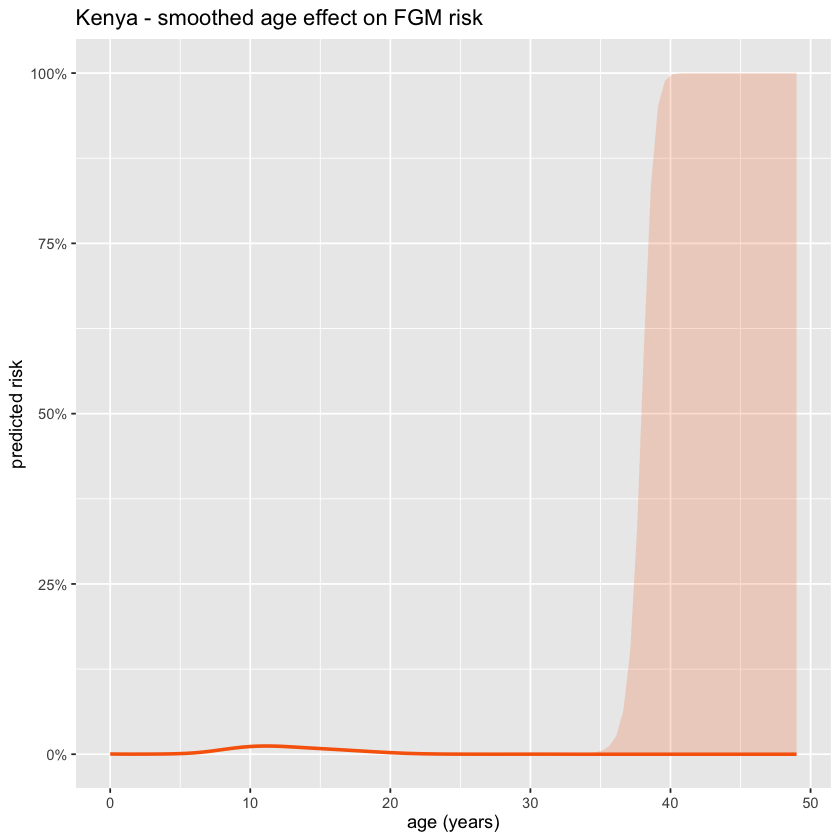

In [19]:
suppressMessages(library(scales))

# Reference levels for the covariates NOT being plotted — since the model is additive,
# holding these fixed only shifts the curve's baseline, not its shape, so any fixed
# choice works for showing how cohort/age themselves affect risk.
ref_urban_rural <- names(sort(table(cohort_numeric$urban_rural), decreasing = TRUE))[1]
ref_region      <- names(sort(table(cohort_numeric$region), decreasing = TRUE))[1]
ref_record_type <- factor("self", levels = levels(cohort_numeric$record_type))

predict_smooth <- function(var_name, grid_values, other_fixed_at) {
  newdata <- tibble(!!var_name := grid_values) |> bind_cols(other_fixed_at)
  pred <- predict(trend_model, newdata = newdata, type = "link", se.fit = TRUE)
  newdata |>
    mutate(
      fit   = plogis(pred$fit),
      lower = plogis(pred$fit - 1.96 * pred$se.fit),
      upper = plogis(pred$fit + 1.96 * pred$se.fit)
    )
}

cohort_pred <- predict_smooth(
  "cohort_mid",
  seq(min(cohort_numeric$cohort_mid), max(cohort_numeric$cohort_mid), length.out = 100),
  tibble(age_year = median(cohort_numeric$age_year), urban_rural = ref_urban_rural,
         region = ref_region, record_type = ref_record_type)
)

age_pred <- predict_smooth(
  "age_year",
  seq(min(cohort_numeric$age_year), max(cohort_numeric$age_year), length.out = 100),
  tibble(cohort_mid = median(cohort_numeric$cohort_mid), urban_rural = ref_urban_rural,
         region = ref_region, record_type = ref_record_type)
)



p_cohort <- ggplot(cohort_pred, aes(x = cohort_mid, y = fit)) +
  geom_ribbon(aes(ymin = lower, ymax = upper), fill = "#4C6EF5", alpha = 0.2) +
  geom_line(color = "#4C6EF5", linewidth = 1) +
  scale_y_continuous(labels = scales::percent) +
  labs(title = paste(country_name, "- smoothed cohort effect on FGM risk"),
       x = "birth cohort (midpoint year)", y = "predicted risk")

p_age <- ggplot(age_pred, aes(x = age_year, y = fit)) +
  geom_ribbon(aes(ymin = lower, ymax = upper), fill = "#F76707", alpha = 0.2) +
  geom_line(color = "#F76707", linewidth = 1) +
  scale_y_continuous(labels = scales::percent) +
  labs(title = paste(country_name, "- smoothed age effect on FGM risk"),
       x = "age (years)", y = "predicted risk")

print(p_cohort)
print(p_age)


## 10. Subnational small area estimation setup

Prepare the design based direct estimates by region and cohort or period, and load the administrative boundaries and spatial adjacency structure the smoothing step in section 11 needs, following the SUMMER package architecture described in section 2.2 of the improved methodology document.

# Direct estimates per source

#old code

In [20]:
# direct_self <- survey::svyby(
#   ~event, ~region + birth_cohort,
#   subset(hazard_design, record_type == "self"), survey::svymean, na.rm = TRUE
# ) |> dplyr::mutate(record_type = "self")

# direct_daughter <- survey::svyby(
#   ~event, ~region + birth_cohort,
#   subset(hazard_design, record_type == "daughter"), survey::svymean, na.rm = TRUE
# ) |> dplyr::mutate(record_type = "daughter")

# readr::write_csv(direct_self,     file.path(output_dir, paste0(country_iso3, "_direct_estimates_self.csv")))
# readr::write_csv(direct_daughter, file.path(output_dir, paste0(country_iso3, "_direct_estimates_daughter.csv")))

# if (run_spatial_model) {
#   boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid()
#   adjacency  <- spdep::poly2nb(boundaries, row.names = boundaries[[region_var_shapefile]])
#   adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)
#   cat("Loaded", nrow(boundaries), "regions and built the adjacency matrix\n")
# } else {
#   cat("Spatial model disabled for this run, skip boundary and adjacency loading\n")
# }


#final-age band specific cumulative risk

In [21]:
surv_at_t <- function(km_fit, t) {
  if (t <= 0) return(list(surv = 1, varlog = 0))
  before <- which(km_fit$time <= t)
  if (length(before) == 0) return(list(surv = 1, varlog = 0))
  idx <- max(before)
  list(surv = km_fit$surv[idx], varlog = km_fit$varlog[idx])
}

age_band_cutpoints <- c(0, 5, 10, 15, 20, 25)
age_band_levels <- paste0(age_band_cutpoints[-length(age_band_cutpoints)], "-", age_band_cutpoints[-1])

region_age_band_risks <- function(fit_r, cutpoints, max_observed) {
  s <- lapply(cutpoints, function(t) surv_at_t(fit_r, t))
  purrr::map2_dfr(seq_along(cutpoints)[-length(cutpoints)], seq_along(cutpoints)[-1], function(i, j) {
    band_label <- paste0(cutpoints[i], "-", cutpoints[j])
    is_complete <- max_observed >= cutpoints[j]

    if (max_observed <= cutpoints[i]) {
      return(tibble::tibble(age_band = band_label, event = NA_real_, se = NA_real_,
                              provisional_event = NA_real_, provisional_se = NA_real_,
                              observed_to_age = NA_real_, is_complete = FALSE))
    }
    s0 <- s[[i]]
    if (s0$surv <= 0) {
      return(tibble::tibble(age_band = band_label, event = NA_real_, se = NA_real_,
                              provisional_event = NA_real_, provisional_se = NA_real_,
                              observed_to_age = NA_real_, is_complete = FALSE))
    }

    # Risk up to whatever age has actually been observed -- real information
    # even when the cohort hasn't reached the band's end yet (e.g. infant
    # cutting already visible in the youngest cohort). Kept in separate
    # provisional_* columns so the spatial model, which needs strictly
    # comparable completed bands, is unaffected.
    s_obs <- surv_at_t(fit_r, min(max_observed, cutpoints[j]))
    cond_surv_obs <- s_obs$surv / s0$surv
    var_log_obs   <- max(s_obs$varlog - s0$varlog, 0)
    provisional_event <- 1 - cond_surv_obs
    provisional_se    <- cond_surv_obs * sqrt(var_log_obs)

    if (!is_complete) {
      return(tibble::tibble(age_band = band_label, event = NA_real_, se = NA_real_,
                              provisional_event = provisional_event, provisional_se = provisional_se,
                              observed_to_age = min(max_observed, cutpoints[j]), is_complete = FALSE))
    }

    s1 <- s[[j]]
    cond_surv <- s1$surv / s0$surv
    var_log_cond <- max(s1$varlog - s0$varlog, 0)
    tibble::tibble(age_band = band_label, event = 1 - cond_surv, se = cond_surv * sqrt(var_log_cond),
                    provisional_event = 1 - cond_surv, provisional_se = cond_surv * sqrt(var_log_cond),
                    observed_to_age = cutpoints[j], is_complete = TRUE)
  })
}

compute_cohort_region_age_band_risk <- function(record_data, record_label) {
  design <- survey::svydesign(ids = ~cluster, strata = ~interaction(survey_year, region), weights = ~weight, data = record_data, nest = TRUE)
  cells <- record_data |> dplyr::distinct(region, birth_cohort)
  purrr::pmap_dfr(cells, function(region, birth_cohort) {
    target_region <- region; target_cohort <- birth_cohort
    cell_data <- record_data |> dplyr::filter(region == target_region, birth_cohort == target_cohort)
    if (nrow(cell_data) == 0) return(tibble::tibble())
    max_observed <- max(cell_data$time, na.rm = TRUE)
    if (sum(cell_data$fgm_event, na.rm = TRUE) == 0) {
      risks <- purrr::map_dfr(seq_len(length(age_band_cutpoints) - 1), function(i) {
        band_label <- paste0(age_band_cutpoints[i], "-", age_band_cutpoints[i + 1])
        is_complete <- max_observed >= age_band_cutpoints[i + 1]
        if (!is_complete) {
          tibble::tibble(age_band = band_label, event = NA_real_, se = NA_real_,
                          provisional_event = 0, provisional_se = 0,
                          observed_to_age = max_observed, is_complete = FALSE)
        } else {
          tibble::tibble(age_band = band_label, event = 0, se = 0,
                          provisional_event = 0, provisional_se = 0,
                          observed_to_age = age_band_cutpoints[i + 1], is_complete = TRUE)
        }
      })
      return(risks |> dplyr::mutate(region = target_region, birth_cohort = target_cohort,
                                     sum_weight = sum(cell_data$weight, na.rm = TRUE)))
    }
    sub_design <- tryCatch(subset(design, region == target_region & birth_cohort == target_cohort), error = function(e) NULL)
    if (is.null(sub_design)) return(tibble::tibble())
    fit_r <- tryCatch(survey::svykm(survival::Surv(time, fgm_event) ~ 1, design = sub_design, se = TRUE), error = function(e) NULL)
    if (is.null(fit_r)) return(tibble::tibble())
    region_age_band_risks(fit_r, age_band_cutpoints, max_observed) |>
      dplyr::mutate(region = target_region, birth_cohort = target_cohort,
                     sum_weight = sum(cell_data$weight, na.rm = TRUE))
  }) |> dplyr::mutate(record_type = record_label)
}

full_risk_self     <- compute_cohort_region_age_band_risk(fgm_events |> dplyr::filter(record_type == "self"), "self")
full_risk_daughter <- compute_cohort_region_age_band_risk(fgm_events |> dplyr::filter(record_type == "daughter"), "daughter")

readr::write_csv(full_risk_self,     file.path(output_dir, paste0(country_iso3, "_cohort_age_band_risk_self.csv")))
readr::write_csv(full_risk_daughter, file.path(output_dir, paste0(country_iso3, "_cohort_age_band_risk_daughter.csv")))


## 11. Spatial and temporal modeling

Bayesian spatial and temporal smoothing through INLA, a structured (BYM2) spatial random effect over regions plus a second order random walk over birth cohort or period, letting sparse regions borrow strength from their neighbours and from adjacent periods, the SUMMER style small area hazard framework recommended in section 2.2 of the improved methodology document. `SUMMER::smoothDirect()` offers a ready made wrapper for the same architecture if the outcome is reframed as a rate, the explicit INLA formula below is written out in full for transparency and easier adaptation.

# USING INLA

## 12. Risk maps

Map the smoothed subnational estimates to show where risk is concentrated, addressing the cross border clustering the original UNFPA presentation highlighted for Ethiopia, Kenya, and Somalia.

1. The darker cells in 2010–2024 reflect two things layered together: (1) daughters are only recently born, so nearly all their observed years fall in the 0–4 age band, where FGM risk is genuinely highest.
2. Cutting is  shifting to earlier years of the daughters life

#INLA BORROWING SUMMER STRENGTHS-REPLICATING SUMMER'S PRECISION WEIGHTING IDEA

In [22]:
if (run_spatial_model) {
  boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid()
  boundary_region_keys <- standardize_region(boundaries[[region_var_shapefile]])
  adjacency  <- spdep::poly2nb(boundaries, row.names = boundary_region_keys)
  adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)

  fit_bym2_rw2_one_band <- function(band_data) {
    eps <- 1e-4
    d <- band_data |>
      tidyr::drop_na(event, se) |>
      dplyr::mutate(
        birth_cohort = droplevels(birth_cohort),
        region_id    = match(standardize_region(region), boundary_region_keys),
        cohort_id    = as.integer(birth_cohort),
        p            = pmin(pmax(event, eps), 1 - eps),
        se_p         = pmax(se, eps),
        logit_est    = qlogis(p),
        logit_prec   = pmin(((p * (1 - p))^2) / (se_p^2), 1e6)
      )
    fit <- INLA::inla(
      logit_est ~ f(region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE) + f(cohort_id, model = "rw2"),
      family = "gaussian", data = d, scale = d$logit_prec,
      control.family = list(hyper = list(prec = list(fixed = TRUE, initial = 0))),
      control.predictor = list(compute = TRUE), control.compute = list(dic = TRUE, waic = TRUE)
    )
    d |> dplyr::mutate(
      smoothed_risk = plogis(fit$summary.fitted.values$mean),
      lower_ci      = plogis(fit$summary.fitted.values$`0.025quant`),
      upper_ci      = plogis(fit$summary.fitted.values$`0.975quant`)
    )
  }

  fit_band_if_enough_data <- function(full_risk, band, source_label) {
    band_data <- full_risk |> dplyr::filter(age_band == band)
    clean_data <- tidyr::drop_na(band_data, event, se)
    n_cohorts <- dplyr::n_distinct(clean_data$birth_cohort)
    if (nrow(clean_data) < 5 || n_cohorts < 3) {
      cat("Skipping", source_label, "ages", band, "-- only", n_cohorts, "cohort(s) with real data, not enough for RW2 smoothing\n")
      return(tibble::tibble())
    }
    fit_bym2_rw2_one_band(band_data) |> dplyr::mutate(age_band = band)
  }

  smoothed_by_band_self <- purrr::map_dfr(age_band_levels, ~ fit_band_if_enough_data(full_risk_self, .x, "self"))
  smoothed_by_band_daughter <- purrr::map_dfr(age_band_levels, ~ fit_band_if_enough_data(full_risk_daughter, .x, "daughter"))

  readr::write_csv(smoothed_by_band_self,     file.path(output_dir, paste0(country_iso3, "_smoothed_cohort_age_band_self.csv")))
  readr::write_csv(smoothed_by_band_daughter, file.path(output_dir, paste0(country_iso3, "_smoothed_cohort_age_band_daughter.csv")))
} else {
  message("Spatial model disabled for this run")
}


Skipping daughter ages 5-10 -- only 2 cohort(s) with real data, not enough for RW2 smoothing
Skipping daughter ages 10-15 -- only 1 cohort(s) with real data, not enough for RW2 smoothing
Skipping daughter ages 15-20 -- only 0 cohort(s) with real data, not enough for RW2 smoothing
Skipping daughter ages 20-25 -- only 0 cohort(s) with real data, not enough for RW2 smoothing


In [23]:
if (run_spatial_model) {
  # Provisional spatial map for the 2020-2024 daughter cohort's 0-5 band.
  # Fit independently -- spatial-only BYM2, no RW2-over-cohort, since there's
  # only one cohort here -- so it never influences the three already-
  # validated, completed cohorts' smoothed estimates.
  provisional_cohort <- "2020 to 2024"
  provisional_band   <- "0-5"

  provisional_daughter_direct <- full_risk_daughter |>
    dplyr::filter(age_band == provisional_band, birth_cohort == provisional_cohort) |>
    dplyr::filter(!is.na(provisional_event))

  eps <- 1e-4
  provisional_daughter_d <- provisional_daughter_direct |>
    dplyr::mutate(
      region_id  = match(standardize_region(region), boundary_region_keys),
      p          = pmin(pmax(provisional_event, eps), 1 - eps),
      se_p       = pmax(provisional_se, eps),
      logit_est  = qlogis(p),
      logit_prec = pmin(((p * (1 - p))^2) / (se_p^2), 1e6)
    )

  provisional_fit <- INLA::inla(
    logit_est ~ f(region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE),
    family = "gaussian", data = provisional_daughter_d, scale = provisional_daughter_d$logit_prec,
    control.family = list(hyper = list(prec = list(fixed = TRUE, initial = 0))),
    control.predictor = list(compute = TRUE), control.compute = list(dic = TRUE, waic = TRUE)
  )

  provisional_daughter_smoothed <- provisional_daughter_d |>
    dplyr::mutate(
      smoothed_risk = plogis(provisional_fit$summary.fitted.values$mean),
      lower_ci      = plogis(provisional_fit$summary.fitted.values$`0.025quant`),
      upper_ci      = plogis(provisional_fit$summary.fitted.values$`0.975quant`),
      age_band      = provisional_band,
      birth_cohort  = provisional_cohort

      #birth_cohort  = paste0(provisional_cohort, " (provisional, to age ",
                  #            max(provisional_daughter_direct$observed_to_age), ")")
    )

  cat("Provisional 2020-2024 daughter map fit on", nrow(provisional_daughter_smoothed), "regions\n")
  cat("National average provisional risk:", round(mean(provisional_daughter_smoothed$smoothed_risk) * 100, 1), "%\n")
}


Provisional 2020-2024 daughter map fit on 47 regions
National average provisional risk: 0 %


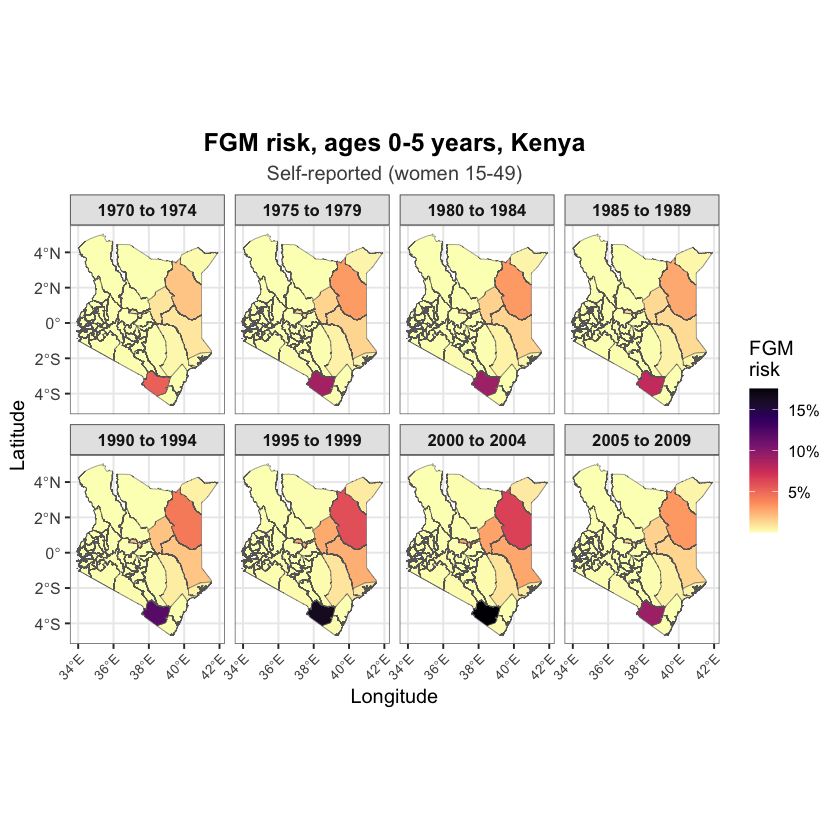

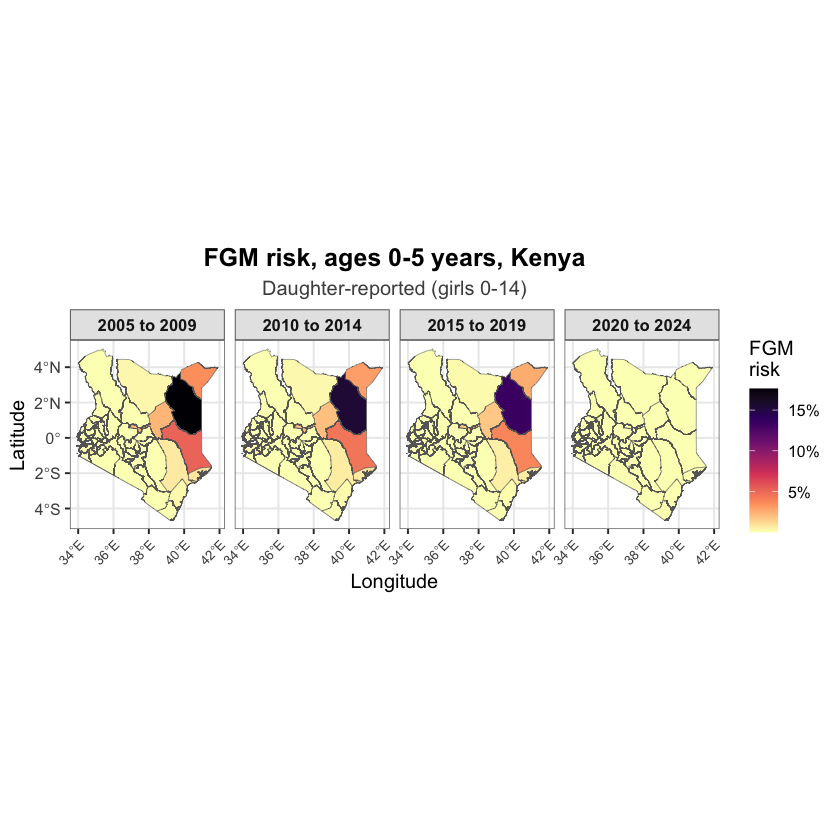

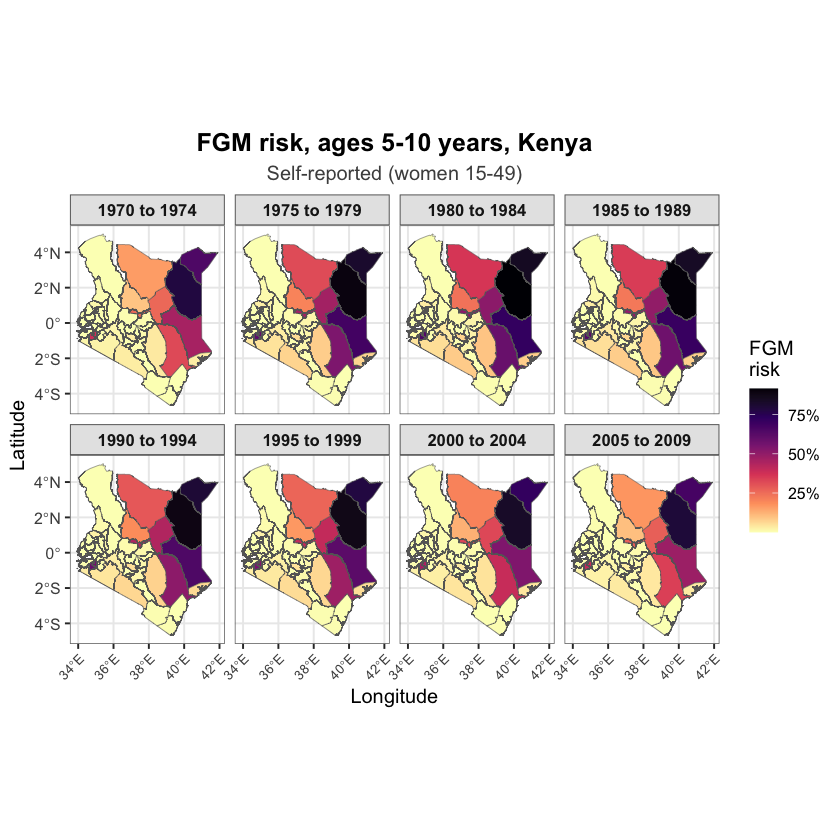

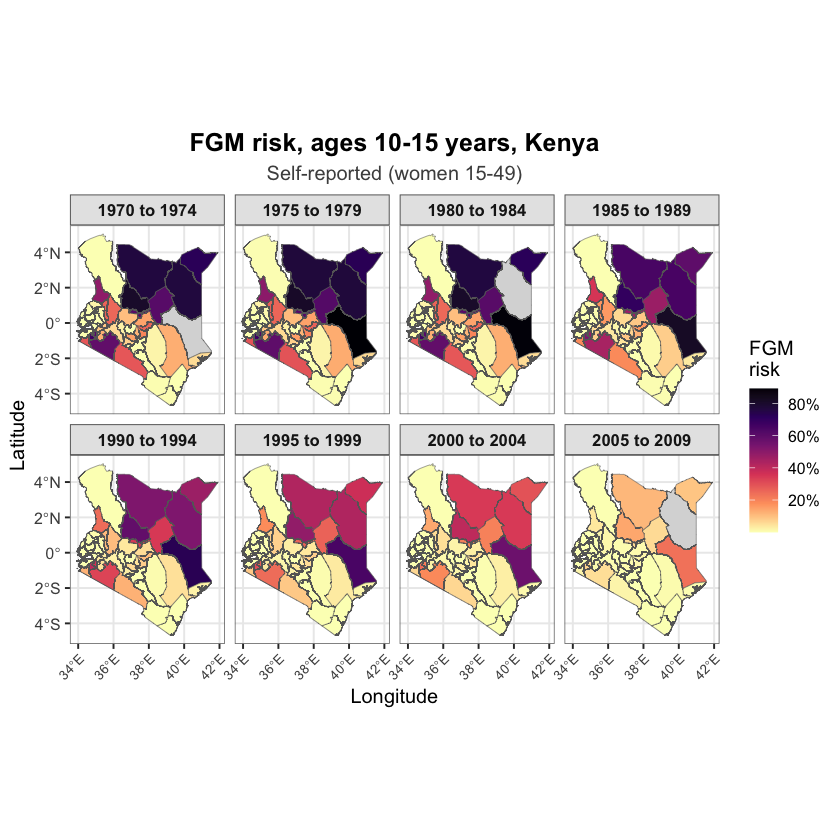

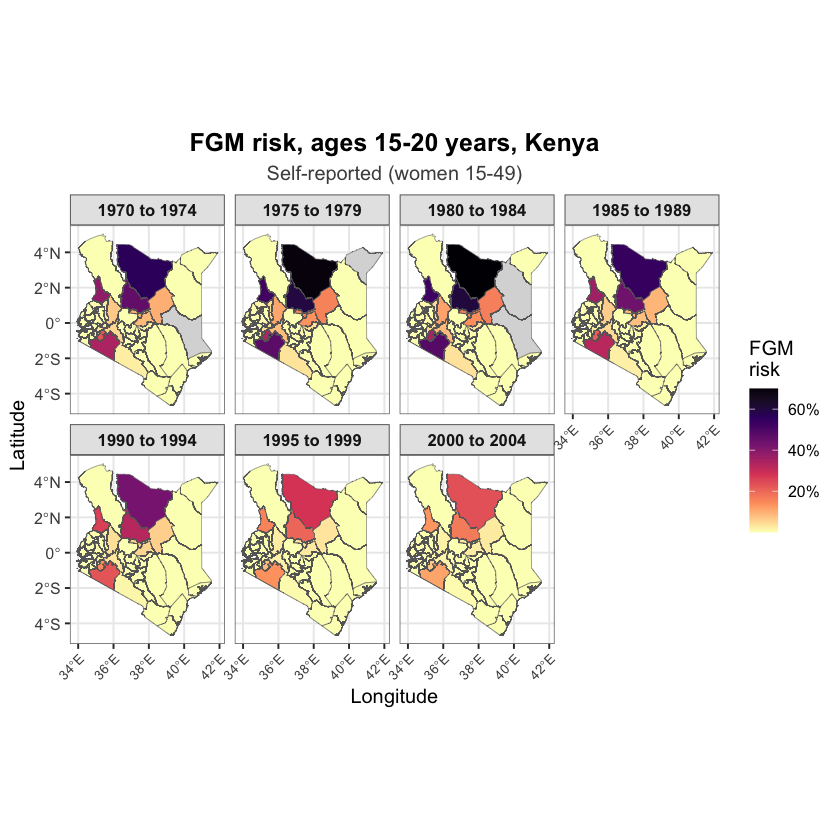

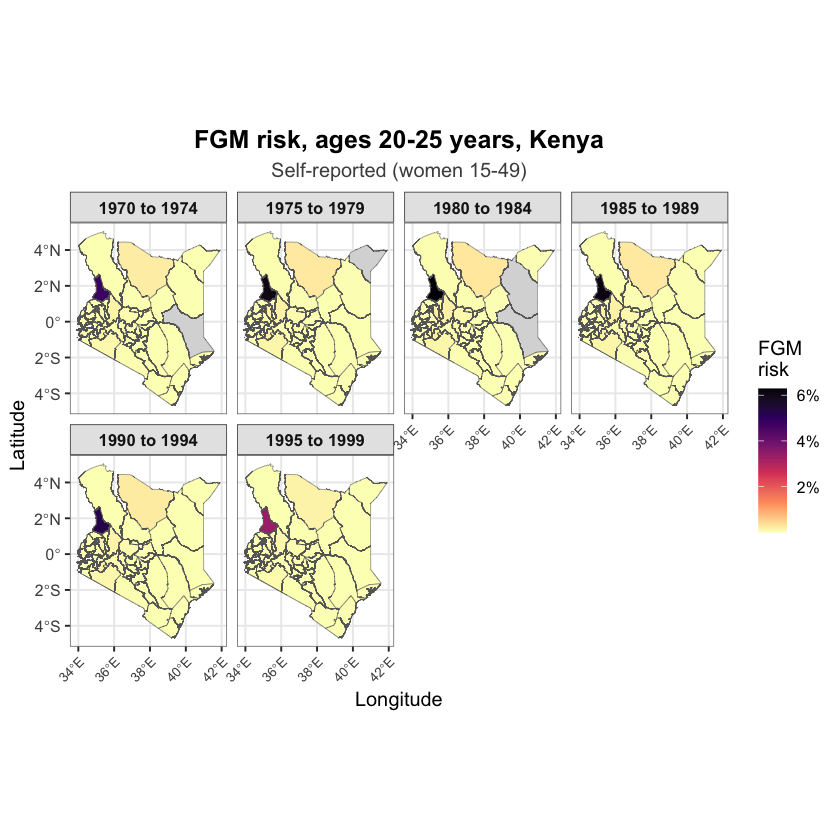

In [24]:
if (run_spatial_model) {
  make_cohort_map_for_band <- function(smoothed_estimates, band_label, source_label) {
    # Every county in every cohort panel, so counties without an estimate for
    # a cohort still show their boundary (filled grey) instead of vanishing.
    estimates <- smoothed_estimates |>
      dplyr::mutate(region = standardize_region(region),
                    birth_cohort = as.character(birth_cohort))
    county_cohort_grid <- tidyr::expand_grid(
      .region_key  = standardize_region(boundaries[[region_var_shapefile]]),
      birth_cohort = sort(unique(estimates$birth_cohort))
    ) |>
      dplyr::left_join(estimates, by = c(".region_key" = "region", "birth_cohort"))

    map_data <- boundaries |>
      dplyr::mutate(.region_key = standardize_region(.data[[region_var_shapefile]])) |>
      dplyr::inner_join(county_cohort_grid, by = ".region_key", relationship = "one-to-many")

    ggplot2::ggplot(map_data) +
      ggplot2::geom_sf(ggplot2::aes(fill = smoothed_risk), color = "grey40", linewidth = 0.15) +
      ggplot2::facet_wrap(~birth_cohort, ncol = 4) +
      ggplot2::scale_fill_viridis_c(name = "FGM\nrisk", option = "magma", direction = -1,
                                      labels = scales::percent_format(accuracy = 1),
                                      na.value = "grey85") +
      ggplot2::labs(title = paste0("FGM risk, ages ", band_label, " years, ", country_name),
                    subtitle = source_label, x = "Longitude", y = "Latitude") +
      ggplot2::theme_bw(base_size = 12) +
      ggplot2::theme(
        plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
        plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
        strip.text = ggplot2::element_text(face = "bold", size = 10),
        strip.background = ggplot2::element_rect(fill = "grey90", color = "grey40"),
        panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
        axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8)
      )
  }

  for (band in age_band_levels) {
    self_band_data <- smoothed_by_band_self |> dplyr::filter(age_band == band)
    if (nrow(self_band_data) > 0) {
      p <- make_cohort_map_for_band(self_band_data, band, "Self-reported (women 15-49)")
      print(p)
      ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_map_ages_", band, "_self.png")), plot = p, width = 12, height = 8, dpi = 300, bg = "white")
    }

    daughter_band_data <- smoothed_by_band_daughter |> dplyr::filter(age_band == band)
    if (band == provisional_band) {
      daughter_band_data <- dplyr::bind_rows(daughter_band_data, provisional_daughter_smoothed)
    }
    if (nrow(daughter_band_data) > 0) {
      p <- make_cohort_map_for_band(daughter_band_data, band, "Daughter-reported (girls 0-14)")
      print(p)
      ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_map_ages_", band, "_daughter.png")), plot = p, width = 12, height = 8, dpi = 300, bg = "white")
    }
  }
}


## 12.1 Covariate-adjusted risk maps

Same maps as Section 12 (same age bands, birth cohorts, counties and design), but the estimates now come from a survey-weighted, covariate-adjusted spatial model. The covariates are the ones used in the covariate-adjusted prevalence and attitude models: ethnicity, wealth, education, religion and urban/rural residence. Section 12 instead smooths design-based Kaplan–Meier estimates.

For each age band and reporting source, a discrete-time hazard model is fitted in INLA on the person-years that fall inside the band:

`logit h = ethnicity + wealth + education + religion + urban_rural + RW2(age in band) + RW2(birth cohort) + BYM2(county)`

- **Weights.** Normalized DHS weights enter as likelihood weights (a pseudo-likelihood), as in the prevalence notebook.
- **Band convention.** A band covers the same ages as the Section 12 Kaplan–Meier ratio S(upper)/S(lower): completed ages lower+1 to upper, and ages 0 to 5 for the first band.
- **Covariates for daughters.** Education, wealth and religion are the mother's.
- **Priors and reference levels.** The fixed effects use weakly informative N(0, 2.5²) priors. Each covariate's reference level is the level with the most cuttings in that band, because band-specific data are sparse and several groups have no cuttings at some ages.
- **Aggregation.** For every posterior draw (500), each girl or woman still uncut at the start of the band gets a band risk of 1 − ∏(1 − h) over the ages in the band. These risks are averaged with DHS weights within each county × cohort cell, giving the posterior mean and 95% interval.
- **Provisional daughter cohort.** The 2020–2024 daughter cohort runs only to the age observed, as in Section 12.

Limitations:
- The cohort trend is shared across groups within a band; there are no covariate × cohort interactions.
- The intervals are pseudo-posterior, not design-based.
- The 0–5 and 20–25 bands rest on very few cuttings, so read them with caution.

In [25]:
if (run_spatial_model) {
  # Respondent-level covariates, the same set used by the covariate-adjusted
  # prevalence (FGM_Prevalence_Incidence_v2, Section 6) and attitude models.
  # fgm_events already carries ethnicity and urban/rural; education, wealth and
  # religion are the respondent's (for daughters, the mother's) and come from
  # the processed prevalence file, keyed on the woman's respondent id.
  risk_covariates <- c("ethnicity", "wealth", "education", "religion", "urban_rural")

  prevalence_dir <- file.path(proc_data_dir, "prevalence")
  respondent_covariates <- readRDS(file.path(prevalence_dir, paste0(country_iso3, "_prevalence_self.rds"))) |>
    dplyr::distinct(resp_id, .keep_all = TRUE) |>
    dplyr::select(resp_id, wealth, education, religion)

  risk_covariate_events <- fgm_events |>
    dplyr::mutate(
      # Daughter ids are "<mother resp_id>-d<birth order>".
      resp_id   = stringr::str_remove(id, "-d[0-9]+$"),
      region    = standardize_region(region),
      region_id = match(region, boundary_region_keys)
    ) |>
    dplyr::left_join(respondent_covariates, by = "resp_id") |>
    dplyr::filter(
      !is.na(region_id), is.finite(weight), weight > 0,
      dplyr::if_all(dplyr::all_of(risk_covariates), ~ !is.na(.x))
    ) |>
    dplyr::mutate(dplyr::across(dplyr::all_of(risk_covariates), factor))

  cat("Respondents with complete covariates:",
      nrow(risk_covariate_events), "of", nrow(fgm_events), "\n")
  print(dplyr::count(risk_covariate_events, record_type))

  # Person-year rows with covariates attached. Same construction as Section 5:
  # one row per completed year of age up to cutting or censoring, event = 1 in
  # the year of cutting.
  risk_covariate_person_time <- person_time |>
    dplyr::select(id, record_type, age_year, event) |>
    dplyr::inner_join(
      risk_covariate_events |>
        dplyr::select(id, record_type, region, region_id, cluster, weight,
                      birth_cohort, dplyr::all_of(risk_covariates)),
      by = c("id", "record_type")
    )

  cat("Person-year rows with covariates:", nrow(risk_covariate_person_time), "\n")
} else {
  message("Spatial model disabled for this run")
}

Respondents with complete covariates: 31361 of 31361 
# A tibble: 2 × 2
  record_type     n
  <chr>       <int>
1 daughter    14541
2 self        16820
Person-year rows with covariates: 547986 


In [26]:
if (run_spatial_model) {
  risk_posterior_draws <- 500L

  # One survey-weighted, covariate-adjusted discrete-time hazard model per
  # (source, age band), fitted on the person-years that fall inside the band,
  # then turned into band risk for every girl/woman still uncut at the band's
  # start and aggregated with DHS weights to the region x cohort cells that
  # Section 12 maps.
  #   logit h = covariates (fixed) + RW2 over age within band
  #             + RW2 over birth cohort + BYM2 over region
  # Band risk for an individual = 1 - prod over ages in band of (1 - h).
  # Ages follow the Section 12 Kaplan-Meier convention, S(upper) / S(lower):
  # a band covers cuttings at completed ages lower+1 .. upper (0 .. 5 for the
  # first band), so heaped recall ages 5, 10, 15, 20 fall in the same band as
  # in Section 12 and the two sets of maps are directly comparable.
  # prediction_cells: region, birth_cohort, last_age (the last completed age
  # the band risk runs through; the band's upper age unless provisional).
  fit_covariate_risk_band <- function(source_label, band, prediction_cells, seed) {
    band_lower <- as.integer(stringr::str_extract(band, "^[0-9]+"))
    band_upper <- as.integer(stringr::str_extract(band, "[0-9]+$"))
    first_age  <- if (band_lower == 0L) 0L else band_lower + 1L

    band_person_years <- risk_covariate_person_time |>
      dplyr::filter(record_type == source_label,
                    age_year >= first_age, age_year <= band_upper) |>
      dplyr::mutate(birth_cohort = as.character(birth_cohort))

    cohort_levels <- sort(unique(band_person_years$birth_cohort))
    if (length(cohort_levels) < 3L) {
      cat("Skipping", source_label, "ages", band, "-- fewer than 3 cohorts for RW2\n")
      return(tibble::tibble())
    }

    # Weighted pseudo-likelihood data, collapsed to identical covariate
    # patterns: a weighted binomial on the collapsed counts has exactly the
    # same log-likelihood as the weighted Bernoulli person-year rows.
    model_rows <- band_person_years |>
      dplyr::mutate(pseudo_weight = weight / mean(weight)) |>
      dplyr::group_by(age_year, birth_cohort, region_id, pseudo_weight,
                      dplyr::across(dplyr::all_of(risk_covariates))) |>
      dplyr::summarise(y = sum(event), n_trials = dplyr::n(), .groups = "drop")

    # Everyone uncut at the start of the band, in the cells to be mapped,
    # collapsed to covariate patterns (same pattern -> same predicted risk).
    at_risk_patterns <- band_person_years |>
      dplyr::filter(age_year == first_age) |>
      dplyr::inner_join(
        prediction_cells |> dplyr::mutate(birth_cohort = as.character(birth_cohort)),
        by = c("region", "birth_cohort")
      ) |>
      dplyr::group_by(region, region_id, birth_cohort, last_age,
                      dplyr::across(dplyr::all_of(risk_covariates))) |>
      dplyr::summarise(pattern_weight = sum(weight), n_at_risk = dplyr::n(), .groups = "drop") |>
      dplyr::mutate(pattern_id = dplyr::row_number())

    if (nrow(at_risk_patterns) == 0L) return(tibble::tibble())

    # One NA-outcome row per pattern and age in band: INLA returns their
    # linear predictors without them entering the likelihood.
    prediction_rows <- at_risk_patterns |>
      dplyr::select(pattern_id, birth_cohort, region_id, last_age,
                    dplyr::all_of(risk_covariates)) |>
      dplyr::mutate(n_ages = last_age - first_age + 1L) |>
      tidyr::uncount(n_ages, .id = "age_offset") |>
      dplyr::mutate(age_year = first_age + age_offset - 1L,
                    y = NA_real_, n_trials = 1L, pseudo_weight = 1) |>
      dplyr::select(-age_offset, -last_age)

    model_data <- dplyr::bind_rows(model_rows, prediction_rows) |>
      dplyr::mutate(
        age_id    = age_year - first_age + 1L,
        cohort_id = match(birth_cohort, cohort_levels)
      ) |>
      droplevels()

    # Reference level = the level with the most events in this band, so the
    # intercept is anchored to a well-observed group rather than to a level
    # that may have no cuttings at all at these ages.
    for (covariate in risk_covariates) {
      events_by_level <- tapply(model_rows$y, model_rows[[covariate]], sum)
      events_by_level <- events_by_level[!is.na(events_by_level)]
      model_data[[covariate]] <- stats::relevel(model_data[[covariate]],
                                                ref = names(which.max(events_by_level)))
    }
    prediction_index <- which(!is.na(model_data$pattern_id))

    risk_formula <- stats::as.formula(paste(
      "y ~", paste(risk_covariates, collapse = " + "), "+",
      "f(age_id, model = 'rw2', constr = TRUE, scale.model = TRUE) +",
      "f(cohort_id, model = 'rw2', constr = TRUE, scale.model = TRUE) +",
      "f(region_id, model = 'bym2', graph = adjacency_matrix, scale.model = TRUE)"
    ))

    fit <- INLA::inla(
      risk_formula, family = "binomial", data = model_data,
      Ntrials = model_data$n_trials, weights = model_data$pseudo_weight,
      control.predictor = list(compute = TRUE, link = 1),
      control.compute = list(dic = TRUE, waic = TRUE, config = TRUE),
      # Weakly informative N(0, 2.5^2) log-odds priors on the covariate
      # effects. Band-specific data are sparse (few early- or late-age
      # cuttings, several groups with none), and INLA's default near-flat
      # prior lets unidentified effects drift to extreme draws that inflate
      # the posterior-mean risk.
      control.fixed = list(prec = 1 / 2.5^2),
      control.inla = list(control.vb = list(enable = FALSE))
    )

    set.seed(seed)
    posterior_samples <- INLA::inla.posterior.sample(
      risk_posterior_draws, fit,
      selection = list(Predictor = prediction_index),
      use.improved.mean = FALSE, skew.corr = FALSE
    )

    pattern_of_row <- model_data$pattern_id[prediction_index]
    cell_key <- paste(at_risk_patterns$region, at_risk_patterns$birth_cohort, sep = "||")
    cell_levels <- unique(cell_key)
    cell_of_pattern <- match(cell_key, cell_levels)
    pattern_weight <- at_risk_patterns$pattern_weight

    # Draws x cells matrix of weighted mean band risk.
    risk_draws <- vapply(posterior_samples, function(sample_draw) {
      log_survival <- stats::plogis(as.numeric(sample_draw$latent[, 1L]), lower.tail = FALSE, log.p = TRUE)
      pattern_risk <- -expm1(rowsum(log_survival, pattern_of_row, reorder = TRUE)[, 1L])
      as.numeric(rowsum(pattern_weight * pattern_risk, cell_of_pattern, reorder = TRUE) /
                   rowsum(pattern_weight, cell_of_pattern, reorder = TRUE))
    }, numeric(length(cell_levels)))
    if (is.null(dim(risk_draws))) risk_draws <- matrix(risk_draws, nrow = length(cell_levels))

    cell_totals <- at_risk_patterns |>
      dplyr::group_by(region, birth_cohort, last_age) |>
      dplyr::summarise(n_at_risk = sum(n_at_risk), sum_weight_at_risk = sum(pattern_weight), .groups = "drop")

    tibble::tibble(
      region        = sub("\\|\\|.*$", "", cell_levels),
      birth_cohort  = sub("^.*\\|\\|", "", cell_levels),
      smoothed_risk = rowMeans(risk_draws),
      lower_ci      = apply(risk_draws, 1L, stats::quantile, probs = 0.025, names = FALSE),
      upper_ci      = apply(risk_draws, 1L, stats::quantile, probs = 0.975, names = FALSE)
    ) |>
      dplyr::left_join(cell_totals, by = c("region", "birth_cohort")) |>
      dplyr::mutate(age_band = band, record_type = source_label,
                    person_years_used = sum(model_rows$n_trials),
                    events_used = sum(model_rows$y), waic = fit$waic$waic)
  }

  # Same region x cohort x band cells as the Section 12 maps.
  complete_cells <- function(smoothed) {
    smoothed |>
      dplyr::distinct(region, birth_cohort, age_band) |>
      dplyr::mutate(region = standardize_region(region),
                    birth_cohort = as.character(birth_cohort),
                    last_age = as.integer(stringr::str_extract(age_band, "[0-9]+$")))
  }
  self_cells     <- complete_cells(smoothed_by_band_self)
  daughter_cells <- dplyr::bind_rows(
    complete_cells(smoothed_by_band_daughter),
    # Provisional youngest daughter cohort: risk only up to the age observed,
    # as in the Section 12 provisional map.
    provisional_daughter_direct |>
      dplyr::transmute(region = standardize_region(region),
                       birth_cohort = as.character(birth_cohort), age_band,
                       last_age = as.integer(pmin(observed_to_age,
                         as.integer(stringr::str_extract(age_band, "[0-9]+$")))))
  )

  fit_bands_for_source <- function(cells, source_label, seed_offset) {
    purrr::imap_dfr(unique(cells$age_band), function(band, i) {
      cat("Fitting covariate-adjusted", source_label, "model, ages", band, "\n")
      fit_covariate_risk_band(source_label, band,
                              cells |> dplyr::filter(age_band == band),
                              seed = 20260924L + seed_offset + i)
    })
  }

  covariate_risk_self     <- fit_bands_for_source(self_cells, "self", 0L)
  covariate_risk_daughter <- fit_bands_for_source(daughter_cells, "daughter", 100L)

  readr::write_csv(covariate_risk_self,
                   file.path(output_dir, paste0(country_iso3, "_covariate_adjusted_cohort_age_band_self.csv")))
  readr::write_csv(covariate_risk_daughter,
                   file.path(output_dir, paste0(country_iso3, "_covariate_adjusted_cohort_age_band_daughter.csv")))

  cat("\nModel summary by band:\n")
  dplyr::bind_rows(covariate_risk_self, covariate_risk_daughter) |>
    dplyr::group_by(record_type, age_band) |>
    dplyr::summarise(cells = dplyr::n(), person_years = dplyr::first(person_years_used),
                     events = dplyr::first(events_used),
                     weighted_mean_risk = stats::weighted.mean(smoothed_risk, sum_weight_at_risk),
                     .groups = "drop") |>
    print()
} else {
  message("Spatial model disabled for this run")
}

Fitting covariate-adjusted self model, ages 0-5 
Fitting covariate-adjusted self model, ages 5-10 
Fitting covariate-adjusted self model, ages 10-15 
Fitting covariate-adjusted self model, ages 15-20 
Fitting covariate-adjusted self model, ages 20-25 
Fitting covariate-adjusted daughter model, ages 0-5 

Model summary by band:
# A tibble: 6 × 6
  record_type age_band cells person_years events weighted_mean_risk
  <chr>       <chr>    <int>        <int>  <int>              <dbl>
1 daughter    0-5        188        73075    128            0.00473
2 self        0-5        376       100705    159            0.00777
3 self        10-15      373        70111   1253            0.0579 
4 self        15-20      325        57125    340            0.0243 
5 self        20-25      278        43484     29            0.00423
6 self        5-10       376        79991   2164            0.0683 


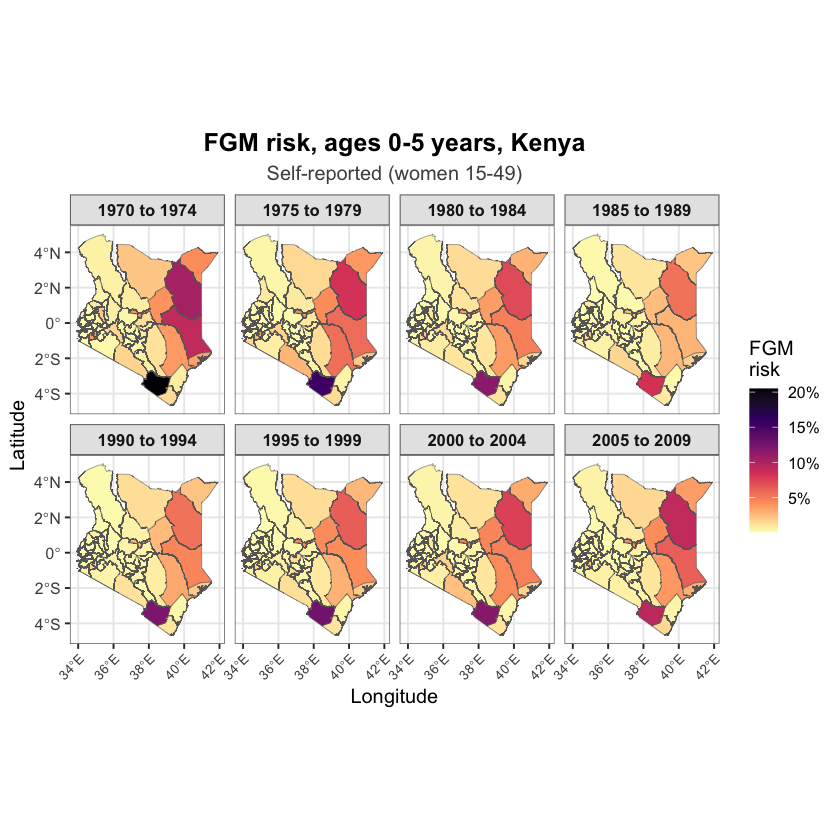

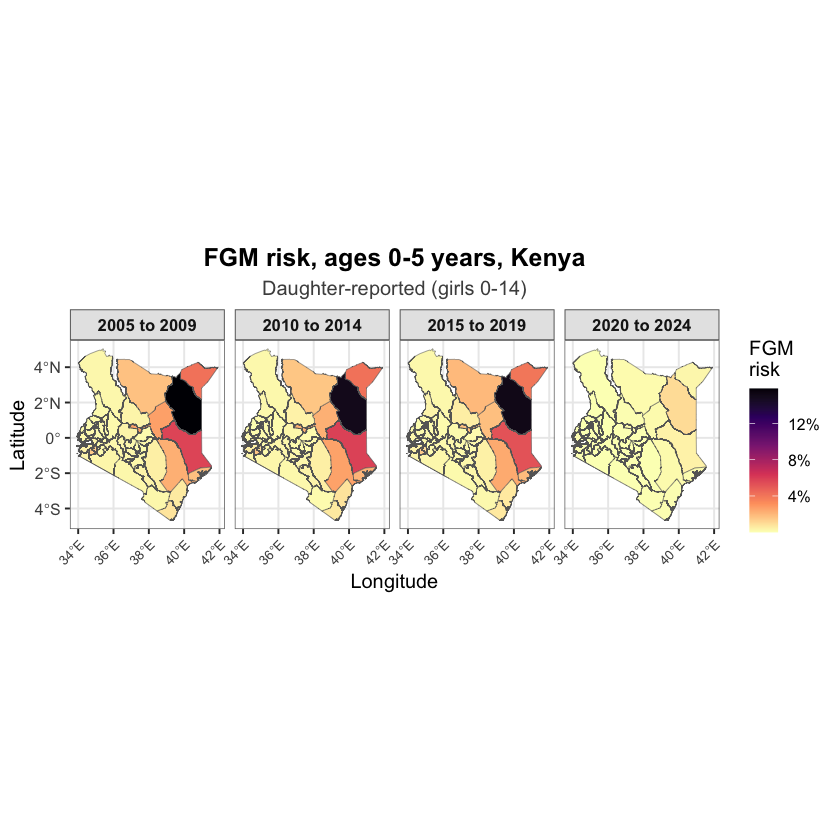

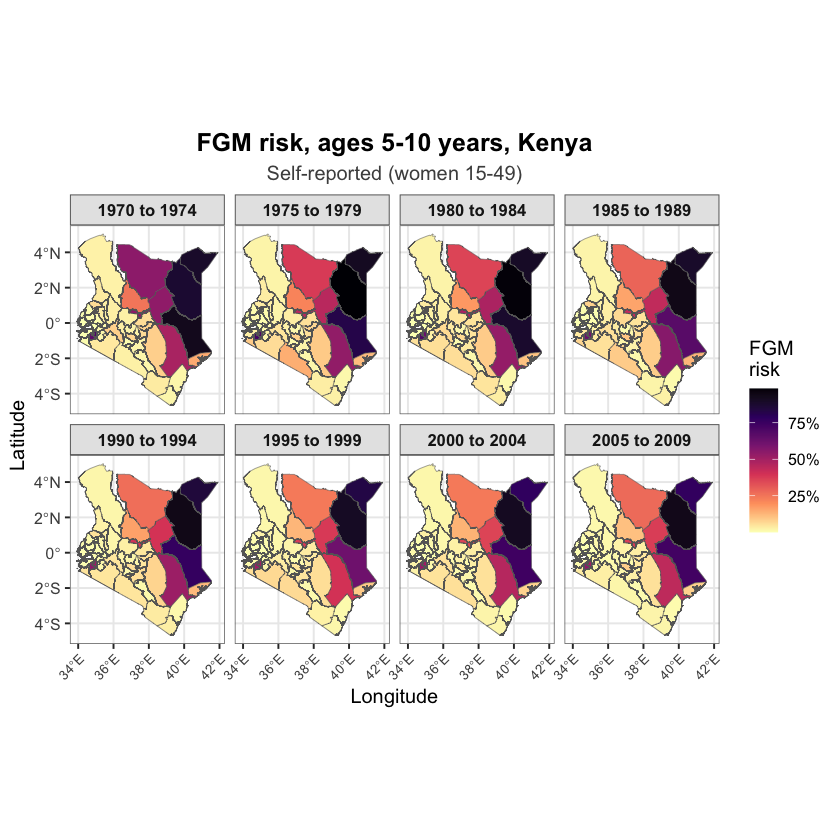

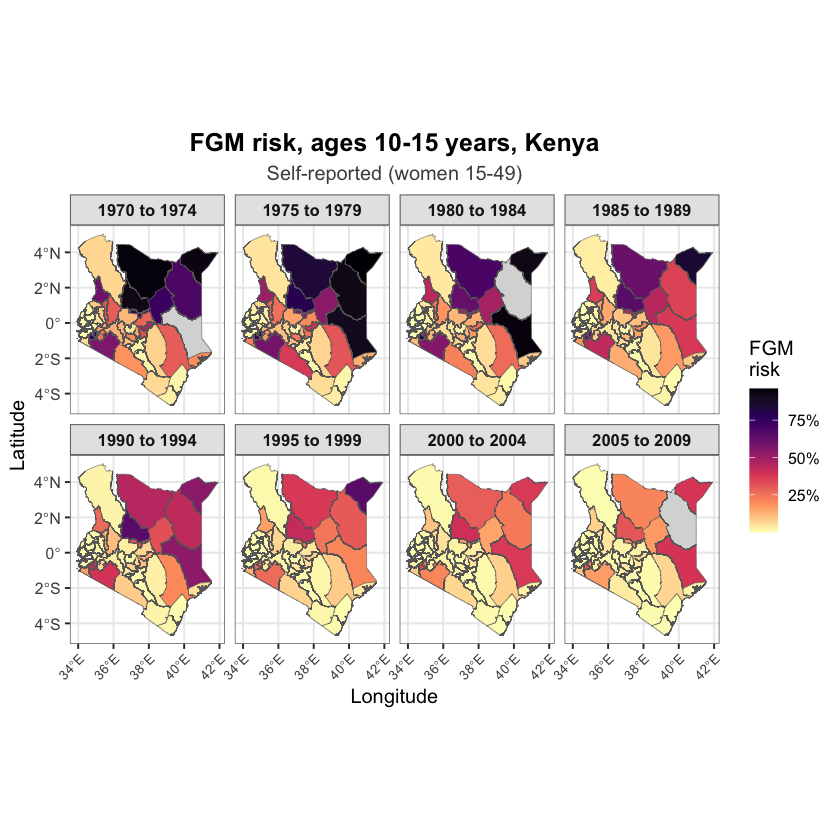

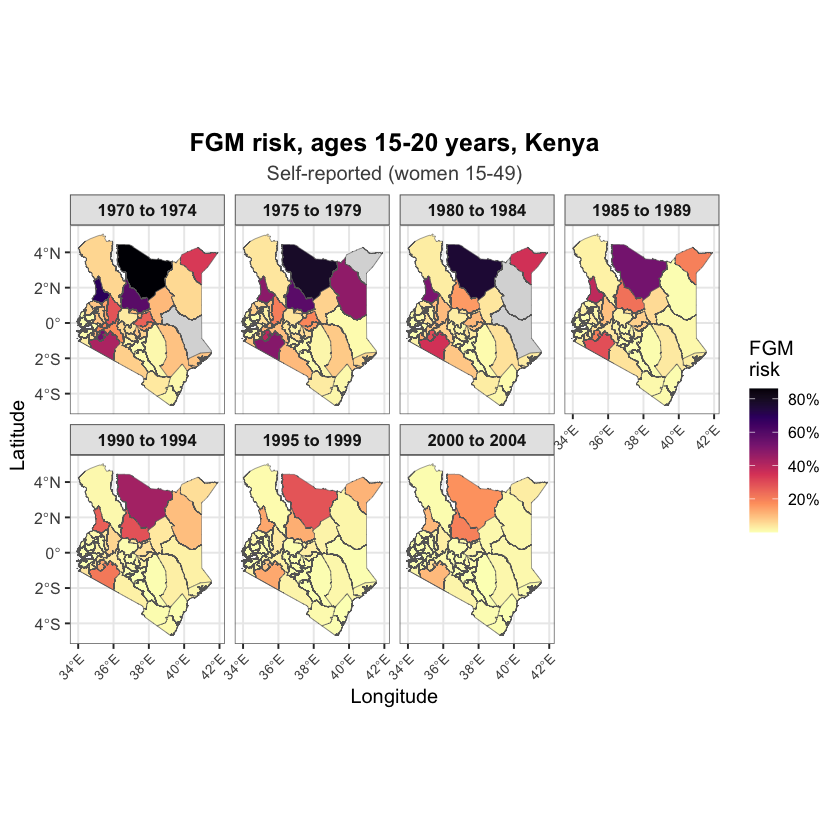

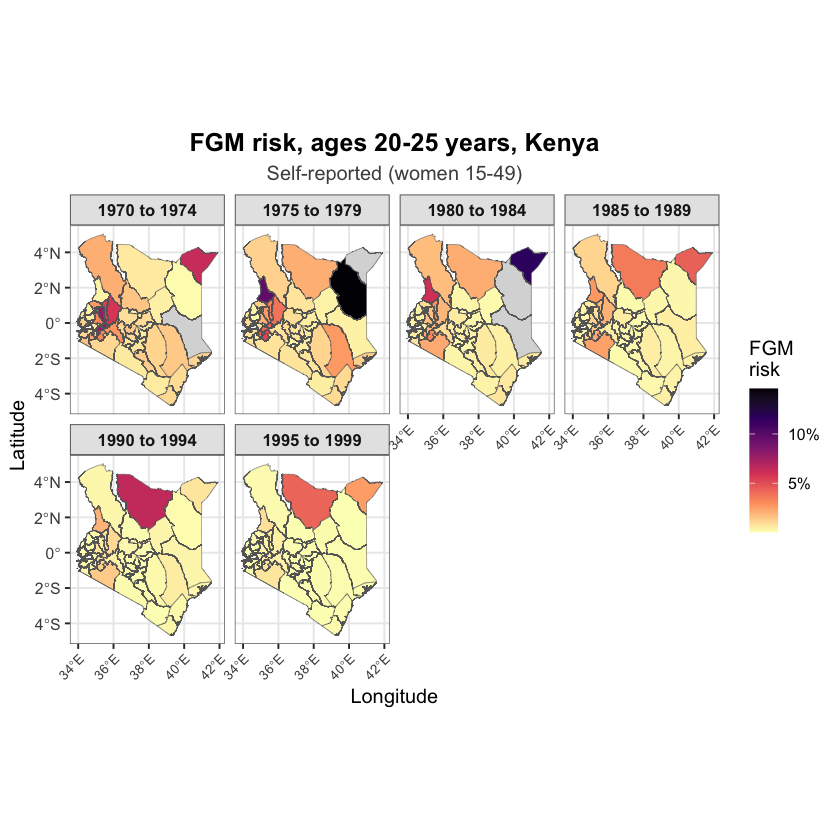

In [27]:
if (run_spatial_model) {
  # Same map function and layout as Section 12; only the title changes, so
  # the two sets of maps can be compared side by side.
  make_covariate_cohort_map_for_band <- function(estimates, band_label, source_label) {
    make_cohort_map_for_band(estimates, band_label, source_label) +
      ggplot2::labs(title = paste0("FGM risk, ages ", band_label,
                                   " years, ", country_name))
  }

  for (band in age_band_levels) {
    self_band_data <- covariate_risk_self |> dplyr::filter(age_band == band)
    if (nrow(self_band_data) > 0) {
      p <- make_covariate_cohort_map_for_band(self_band_data, band, "Self-reported (women 15-49)")
      print(p)
      ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_covariate_map_ages_", band, "_self.png")),
                      plot = p, width = 12, height = 8, dpi = 300, bg = "white")
    }

    daughter_band_data <- covariate_risk_daughter |> dplyr::filter(age_band == band)
    if (nrow(daughter_band_data) > 0) {
      p <- make_covariate_cohort_map_for_band(daughter_band_data, band, "Daughter-reported (girls 0-14)")
      print(p)
      ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_covariate_map_ages_", band, "_daughter.png")),
                      plot = p, width = 12, height = 8, dpi = 300, bg = "white")
    }
  }
}

## 13. Lexis heatmap

A single Lexis surface per country shows age, period, and cohort patterns together, replacing the several separate Kaplan Meier line charts the original presentation used, following section 2.4 of the improved methodology document.

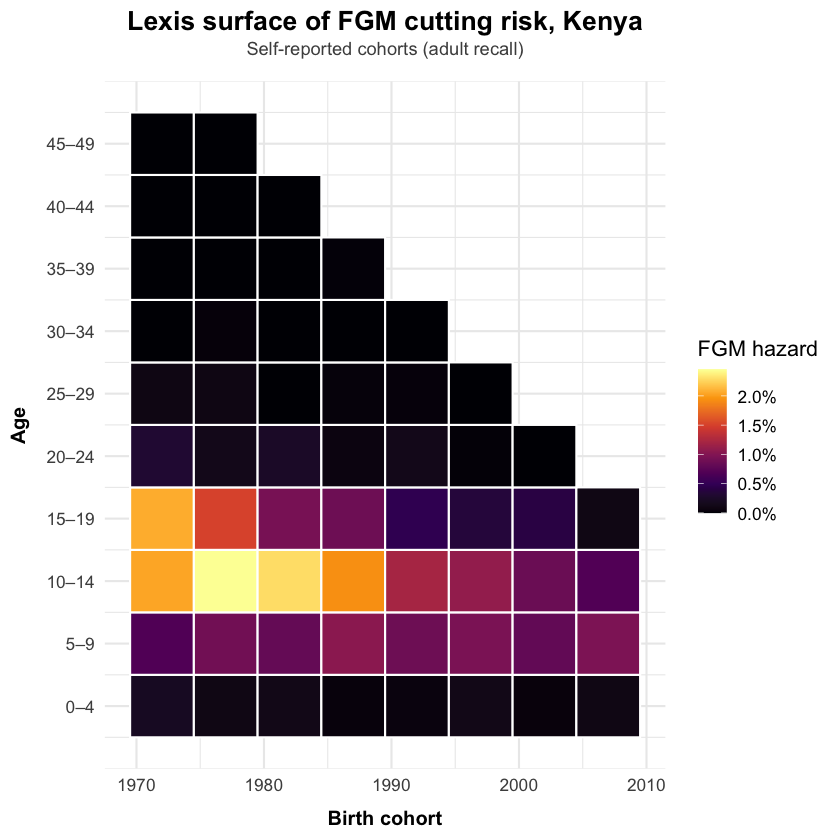

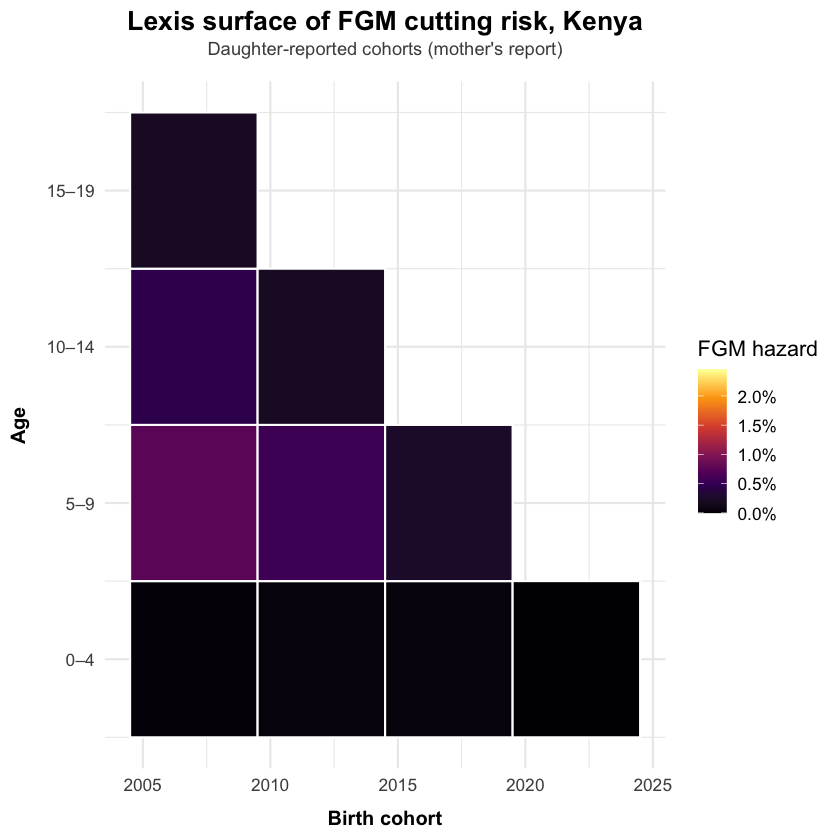

In [28]:
build_lexis_grid <- function(data) {
  data |>
    dplyr::mutate(
      age_band = cut(age_year, breaks = seq(0, 50, by = 5), right = FALSE),
      age_band_mid = as.numeric(stringr::str_extract(age_band, "[0-9]+")) + 2.5
    ) |>
    dplyr::group_by(age_band_mid, cohort_mid) |>
    dplyr::summarise(hazard = weighted.mean(event, weight, na.rm = TRUE), .groups = "drop")
}

lexis_grid_self     <- build_lexis_grid(cohort_numeric |> dplyr::filter(record_type == "self"))
lexis_grid_daughter <- build_lexis_grid(cohort_numeric |> dplyr::filter(record_type == "daughter"))
hazard_limits <- range(c(lexis_grid_self$hazard, lexis_grid_daughter$hazard), na.rm = TRUE)

build_lexis_plot <- function(lexis_grid, subtitle_label, file_suffix) {
  p <- ggplot2::ggplot(lexis_grid, ggplot2::aes(x = cohort_mid, y = age_band_mid, fill = hazard)) +
    ggplot2::geom_tile(width = 5, height = 5, color = "white", linewidth = 0.6) +
    ggplot2::scale_fill_viridis_c(name = "FGM hazard", option = "inferno", labels = scales::percent,
                                    limits = hazard_limits, oob = scales::squish) +
    ggplot2::scale_y_continuous(breaks = seq(2.5, 47.5, by = 5),
                                  labels = paste0(seq(0, 45, by = 5), "\u2013", seq(4, 49, by = 5))) +
    ggplot2::labs(
      title = paste("Lexis surface of FGM cutting risk,", country_name),
      subtitle = subtitle_label, x = "Birth cohort", y = "Age"
    ) +
    ggplot2::theme_minimal(base_size = 13) +
    ggplot2::theme(
      plot.title = ggplot2::element_text(face = "bold", hjust = 0.5, size = 16, margin = ggplot2::margin(b = 4)),
      plot.subtitle = ggplot2::element_text(hjust = 0.5, size = 11, color = "grey30", margin = ggplot2::margin(b = 14)),
      axis.title.x = ggplot2::element_text(face = "bold", size = 12, margin = ggplot2::margin(t = 10)),
      axis.title.y = ggplot2::element_text(face = "bold", size = 12, margin = ggplot2::margin(r = 10))
    )
  print(p)
  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_lexis_heatmap_", file_suffix, ".png")),
                   plot = p, width = 8, height = 6)
  p
}

lexis_plot_self     <- build_lexis_plot(lexis_grid_self, "Self-reported cohorts (adult recall)", "self")
lexis_plot_daughter <- build_lexis_plot(lexis_grid_daughter, "Daughter-reported cohorts (mother's report)", "daughter")


# Line Graphs

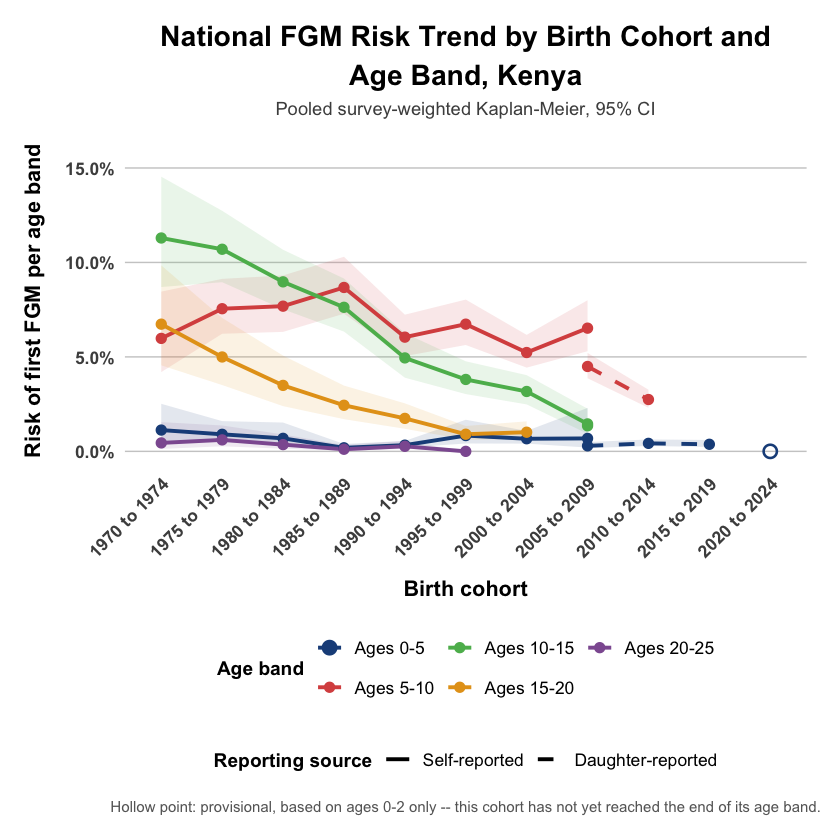

In [29]:
# National FGM risk trend by birth cohort, all age bands together on one set
# of axes -- color = age band, linetype = reporting source.
#
# Built from a pooled, survey-weighted Kaplan-Meier on the whole national
# sample for each source x birth cohort, not from averaging the county
# smoothed estimates (averaging county interval bounds does not give a valid
# national interval). Band risk is 1 - S(upper) / S(lower), the same
# convention as the direct estimates in Section 10: the first band covers
# cuttings at ages 0-5, later bands ages lower+1 .. upper.
#
# Ages are whole years, so the weighted KM is the product over ages of
# (1 - h_a), with h_a = weighted cuttings / weighted girls at risk at age a
# (computed from the Section 5 person-year rows). Standard errors come from
# linearization of the age hazards (svyby, full covariance), which accounts
# for the cluster design. survey::svykm(se = TRUE) gives the same point
# estimate but is far too slow at national scale.
national_km_band_trend <- function(record_label) {
  record_person_time <- person_time |> dplyr::filter(record_type == record_label)
  design <- survey::svydesign(ids = ~cluster, strata = ~interaction(survey_year, region),
                              weights = ~weight, data = record_person_time, nest = TRUE)
  cohorts <- as.character(unique(record_person_time$birth_cohort))

  purrr::map_dfr(cohorts, function(cohort) {
    max_observed <- max(record_person_time$age_year[record_person_time$birth_cohort == cohort])
    age_hazard <- survey::svyby(~event, ~age_year, subset(design, birth_cohort == cohort),
                                survey::svymean, covmat = TRUE)
    hazard_ages <- age_hazard$age_year
    hazard      <- stats::coef(age_hazard)
    hazard_vcov <- stats::vcov(age_hazard)

    purrr::map_dfr(seq_len(length(age_band_cutpoints) - 1L), function(i) {
      band_lower <- age_band_cutpoints[i]
      band_upper <- age_band_cutpoints[i + 1L]
      # Same completeness rule as the direct estimates: the cohort must have
      # been observed to the end of the band.
      if (max_observed < band_upper) return(tibble::tibble())
      first_age <- if (band_lower == 0) 0 else band_lower + 1
      in_band   <- hazard_ages >= first_age & hazard_ages <= band_upper
      h         <- hazard[in_band]
      log_surv  <- sum(log1p(-h))
      gradient  <- -1 / (1 - h)
      se_log    <- sqrt(max(as.numeric(t(gradient) %*% hazard_vcov[in_band, in_band, drop = FALSE] %*% gradient), 0))
      risk      <- -expm1(log_surv)
      risk_se   <- exp(log_surv) * se_log
      # Logit-scale interval so it stays inside [0, 1].
      logit_half <- 1.96 * risk_se / (risk * (1 - risk))
      tibble::tibble(
        birth_cohort = cohort, age_band = age_band_levels[i],
        mean_risk = risk, se = risk_se,
        lower_ci  = if (risk > 0) stats::plogis(stats::qlogis(risk) - logit_half) else 0,
        upper_ci  = if (risk > 0) stats::plogis(stats::qlogis(risk) + logit_half) else 0
      )
    })
  }) |> dplyr::mutate(record_type = record_label)
}

national_km_trend <- dplyr::bind_rows(
  national_km_band_trend("self"),
  national_km_band_trend("daughter")
)
readr::write_csv(national_km_trend,
                 file.path(output_dir, paste0(country_iso3, "_national_km_trend_by_cohort_age_band.csv")))

trend_all_bands <- national_km_trend |>
  dplyr::mutate(
    record_type  = dplyr::recode(record_type, self = "Self-reported", daughter = "Daughter-reported"),
    cohort_start = as.numeric(sub(" .*", "", birth_cohort))
  ) |>
  dplyr::arrange(cohort_start) |>
  dplyr::mutate(
    birth_cohort = factor(birth_cohort, levels = unique(birth_cohort)),
    record_type  = factor(record_type, levels = c("Self-reported", "Daughter-reported")),
    age_band     = factor(age_band, levels = c("0-5", "5-10", "10-15", "15-20", "20-25"),
                            labels = c("Ages 0-5", "Ages 5-10", "Ages 10-15", "Ages 15-20", "Ages 20-25"))
  )

# National-only provisional estimate for the most recent, not-yet-complete
# cohort. Deliberately unsmoothed and national-level: too little follow-up
# per state to spatially smooth yet, but it's real information (e.g. infant
# cutting already observed) that would otherwise be silently dropped.
national_provisional_point <- function(record_data, record_label) {
  cohort_levels <- levels(record_data$birth_cohort)
  latest_cohort <- tail(cohort_levels[cohort_levels %in% as.character(record_data$birth_cohort)], 1)
  cell_data <- record_data |> dplyr::filter(birth_cohort %in% latest_cohort)
  max_observed <- max(cell_data$time, na.rm = TRUE)
  if (max_observed >= 5) return(tibble::tibble())
  design <- survey::svydesign(ids = ~cluster, strata = ~interaction(survey_year, region), weights = ~weight, data = cell_data, nest = TRUE)
  # se=TRUE dropped -- verified it takes 19+ sec for ~2,500 rows and doesn't
  # even finish within a minute for ~8,000 rows, while this function only
  # ever reads the point estimate (no CI is shown for these provisional
  # points), so the variance computation was pure wasted cost.
  fit_r <- survey::svykm(survival::Surv(time, fgm_event) ~ 1, design = design)
  before <- which(fit_r$time <= max_observed)
  surv_obs <- if (length(before) == 0) 1 else fit_r$surv[max(before)]
  tibble::tibble(
    birth_cohort = as.character(latest_cohort),
    mean_risk = 1 - surv_obs, observed_to_age = max_observed,
    record_type = record_label
  )
}

provisional_points <- dplyr::bind_rows(
  national_provisional_point(fgm_events |> dplyr::filter(record_type == "self"),     "Self-reported"),
  national_provisional_point(fgm_events |> dplyr::filter(record_type == "daughter"), "Daughter-reported")
)

# FIX: trend_all_bands's birth_cohort levels stop at the last cohort present
# in the spatially-smoothed data (e.g. "2015 to 2019"), since the provisional
# cohort was deliberately excluded from smoothing. Forcing provisional_points
# onto that same, too-short level set turned "2020 to 2024" into NA (factor()
# maps any value outside its level list to NA) -- which is exactly the extra
# "NA" tick that showed up on the x-axis. Fix: build one shared, chronologically
# sorted level set from BOTH data frames, and apply it to both.
if (nrow(provisional_points) > 0) {
  cohort_levels_combined <- union(levels(trend_all_bands$birth_cohort), unique(provisional_points$birth_cohort))
  cohort_levels_combined <- cohort_levels_combined[order(as.numeric(sub(" .*", "", cohort_levels_combined)))]

  trend_all_bands <- trend_all_bands |>
    dplyr::mutate(birth_cohort = factor(as.character(birth_cohort), levels = cohort_levels_combined))

  provisional_points <- provisional_points |>
    dplyr::mutate(
      birth_cohort = factor(birth_cohort, levels = cohort_levels_combined),
      age_band     = factor("Ages 0-5", levels = levels(trend_all_bands$age_band)),
      record_type  = factor(record_type, levels = levels(trend_all_bands$record_type))
    )
}

y_max <- max(trend_all_bands$upper_ci, provisional_points$mean_risk, na.rm = TRUE)
y_limit <- min(1, ceiling(y_max * 1.1 * 100) / 100)

age_band_colors <- c(
  "Ages 0-5"    = "#1D4E89",
  "Ages 5-10"   = "#D9534F",
  "Ages 10-15"  = "#5CB85C",
  "Ages 15-20"  = "#E5A11C",
  "Ages 20-25"  = "#8E5DA0"
)

trend_plot_all_bands <- ggplot2::ggplot(
  trend_all_bands,
  ggplot2::aes(x = birth_cohort, y = mean_risk, color = age_band, linetype = record_type,
               group = interaction(age_band, record_type))
) +
  ggplot2::geom_ribbon(
    ggplot2::aes(ymin = lower_ci, ymax = upper_ci, fill = age_band, group = interaction(age_band, record_type)),
    alpha = 0.12, color = NA, show.legend = FALSE, na.rm = TRUE
  ) +
  ggplot2::geom_line(linewidth = 1.1, na.rm = TRUE) +
  ggplot2::geom_point(size = 2.4, na.rm = TRUE) +
  ggplot2::geom_point(
    data = provisional_points,
    ggplot2::aes(x = birth_cohort, y = mean_risk, color = age_band, shape = record_type),
    size = 3, stroke = 1.1, fill = NA, inherit.aes = FALSE
  ) +
  ggplot2::scale_color_manual(values = age_band_colors, name = "Age band") +
  ggplot2::scale_fill_manual(values = age_band_colors, guide = "none") +
  ggplot2::scale_linetype_manual(values = c("Self-reported" = "solid", "Daughter-reported" = "dashed"),
                                   name = "Reporting source") +
  ggplot2::scale_shape_manual(values = c("Self-reported" = 1, "Daughter-reported" = 1), guide = "none") +
  ggplot2::scale_y_continuous(
    labels = scales::percent_format(accuracy = 0.1),
    limits = c(0, y_limit),
    breaks = scales::pretty_breaks(n = 6)
  ) +
  ggplot2::labs(
    title = stringr::str_wrap(
      paste("National FGM Risk Trend by Birth Cohort and Age Band,", country_name),
      width = 45
    ),
    subtitle = "Pooled survey-weighted Kaplan-Meier, 95% CI",
    x = "Birth cohort", y = "Risk of first FGM per age band",
    caption = if (nrow(provisional_points) > 0) {
      paste0("Hollow point: provisional, based on ages 0-", max(provisional_points$observed_to_age),
             " only -- this cohort has not yet reached the end of its age band.")
    } else NULL
  ) +
  ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(
    plot.title = ggplot2::element_text(face = "bold", size = 17, hjust = 0.5, lineheight = 1.15, margin = ggplot2::margin(b = 6)),
    plot.subtitle = ggplot2::element_text(size = 11, color = "grey30", hjust = 0.5, margin = ggplot2::margin(b = 10)),
    plot.caption = ggplot2::element_text(size = 9, color = "grey40", hjust = 0.5, margin = ggplot2::margin(t = 10)),
    axis.title.x = ggplot2::element_text(face = "bold", size = 13, margin = ggplot2::margin(t = 12)),
    axis.title.y = ggplot2::element_text(face = "bold", size = 13, margin = ggplot2::margin(r = 12)),
    axis.text.x = ggplot2::element_text(face = "bold", angle = 45, hjust = 1, vjust = 1, size = 10.5),
    axis.text.y = ggplot2::element_text(face = "bold", size = 10.5),
    legend.position = "bottom",
    legend.box = "vertical",
    legend.title = ggplot2::element_text(face = "bold", size = 11.5),
    legend.text = ggplot2::element_text(size = 10.5),
    panel.grid.major.x = ggplot2::element_blank(),
    panel.grid.minor = ggplot2::element_blank(),
    panel.grid.major.y = ggplot2::element_line(color = "grey80", linewidth = 0.4),
    plot.margin = ggplot2::margin(t = 15, r = 20, b = 15, l = 15)
  ) +
  ggplot2::guides(
    color = ggplot2::guide_legend(order = 1, nrow = 2),
    linetype = ggplot2::guide_legend(order = 2)
  )

print(trend_plot_all_bands)

ggplot2::ggsave(
  filename = file.path(output_dir, paste0(country_iso3, "_national_risk_trend_all_bands_combined.png")),
  plot = trend_plot_all_bands, width = 12, height = 8, dpi = 300, bg = "white"
)


In [30]:
# Check: pooled national KM trend against the design-based direct estimates.
# "Direct" = the Section 10 county x cohort Kaplan-Meier band risks averaged
# nationally with their survey weights (the same aggregation Section 15 uses).
# The two should agree closely; large gaps would point to a problem in one of
# them. The county-smoothed average the trend used before is shown alongside.
direct_by_cohort <- dplyr::bind_rows(full_risk_self, full_risk_daughter) |>
  dplyr::filter(is_complete) |>
  dplyr::group_by(record_type, birth_cohort = as.character(birth_cohort), age_band) |>
  dplyr::summarise(direct_risk = weighted.mean(event, w = sum_weight, na.rm = TRUE), .groups = "drop")

smoothed_by_cohort <- if (run_spatial_model) {
  dplyr::bind_rows(smoothed_by_band_self |> dplyr::mutate(record_type = "self"),
                   smoothed_by_band_daughter |> dplyr::mutate(record_type = "daughter")) |>
    dplyr::group_by(record_type, birth_cohort = as.character(birth_cohort), age_band) |>
    dplyr::summarise(smoothed_avg_risk = weighted.mean(smoothed_risk, w = sum_weight, na.rm = TRUE), .groups = "drop")
} else tibble::tibble(record_type = character(), birth_cohort = character(), age_band = character())

trend_check <- national_km_trend |>
  dplyr::select(record_type, birth_cohort, age_band, km_risk = mean_risk, km_lower = lower_ci, km_upper = upper_ci) |>
  dplyr::left_join(direct_by_cohort, by = c("record_type", "birth_cohort", "age_band")) |>
  dplyr::left_join(smoothed_by_cohort, by = c("record_type", "birth_cohort", "age_band")) |>
  dplyr::mutate(
    diff_pts       = 100 * (km_risk - direct_risk),
    direct_in_ci   = direct_risk >= km_lower & direct_risk <= km_upper
  ) |>
  dplyr::arrange(record_type, age_band, birth_cohort)

readr::write_csv(trend_check, file.path(output_dir, paste0(country_iso3, "_national_km_trend_check.csv")))

cat("Cells compared:", nrow(trend_check),
    "| mean absolute difference, pooled KM vs direct:",
    round(mean(abs(trend_check$diff_pts), na.rm = TRUE), 2), "percentage points",
    "| direct estimate inside the KM 95% CI:",
    sum(trend_check$direct_in_ci, na.rm = TRUE), "of", sum(!is.na(trend_check$direct_in_ci)), "\n")

trend_check |>
  dplyr::mutate(dplyr::across(c(km_risk, km_lower, km_upper, direct_risk, smoothed_avg_risk), ~ round(100 * .x, 1)),
                diff_pts = round(diff_pts, 2)) |>
  print(n = Inf)


Cells compared: 43 | mean absolute difference, pooled KM vs direct: 0.42 percentage points | direct estimate inside the KM 95% CI: 40 of 43 


# A tibble: 43 × 10
   record_type birth_cohort age_band km_risk km_lower km_upper direct_risk
   <chr>       <chr>        <chr>      <dbl>    <dbl>    <dbl>       <dbl>
 1 daughter    2005 to 2009 0-5          0.3      0.2      0.5         0.3
 2 daughter    2010 to 2014 0-5          0.4      0.3      0.6         0.4
 3 daughter    2015 to 2019 0-5          0.4      0.2      0.6         0.4
 4 daughter    2005 to 2009 10-15        1.4      0.8      2.1         1.6
 5 daughter    2005 to 2009 5-10         4.5      3.9      5.2         4.4
 6 daughter    2010 to 2014 5-10         2.7      2.3      3.3         2.9
 7 self        1970 to 1974 0-5          1.1      0.5      2.5         1  
 8 self        1975 to 1979 0-5          0.9      0.5      1.6         0.8
 9 self        1980 to 1984 0-5          0.7      0.3      1.5         0.7
10 self        1985 to 1989 0-5          0.2      0.1      0.4         0.2
11 self        1990 to 1994 0-5          0.3      0.2      0.6         0.3
12 se

Use the Kenya estimates generated in the preceding sections to describe cohort change, age at cutting, and county variation. Self-reported and daughter-reported histories should be compared only over common observed ages. The youngest daughter cohorts have incomplete follow-up and must not be interpreted as completed lifetime risk. County estimates with small effective samples or wide intervals require additional caution.

## 14. Change point analysis

Identify the birth cohort or calendar year at which a country's incidence trend meaningfully changed, replacing the qualitative declining versus not declining read used in the original presentation, following section 3 of the improved methodology document.

The series is the self-reported Lexis hazard averaged over ages 0–14 only (bands 0–4, 5–9, 10–14), and only cohorts observed across all three bands are kept. Averaging over every age up to 49 mixes in adult bands where the hazard is near zero. Older cohorts contribute more of those bands, which pulls their average down and can create or hide a trend that is really about age, not cohort.


Loading required package: zoo




Attaching package: ‘zoo’




The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




Successfully loaded changepoint package version 2.3
 See NEWS for details of all changes.



# A tibble: 8 × 3
  cohort_mid n_bands mean_hazard
       <dbl>   <int>       <dbl>
1       1972       3     0.00971
2       1977       3     0.0115 
3       1982       3     0.0107 
4       1987       3     0.0100 
5       1992       3     0.00706
6       1997       3     0.00717
7       2002       3     0.00561
8       2007       3     0.00581
# A tibble: 1 × 4
  country basis                      changepoint_detected estimated_change_coh…¹
  <chr>   <chr>                      <lgl>                                 <dbl>
1 Kenya   self-reported cohorts, me… FALSE                                    NA
# ℹ abbreviated name: ¹​estimated_change_cohort


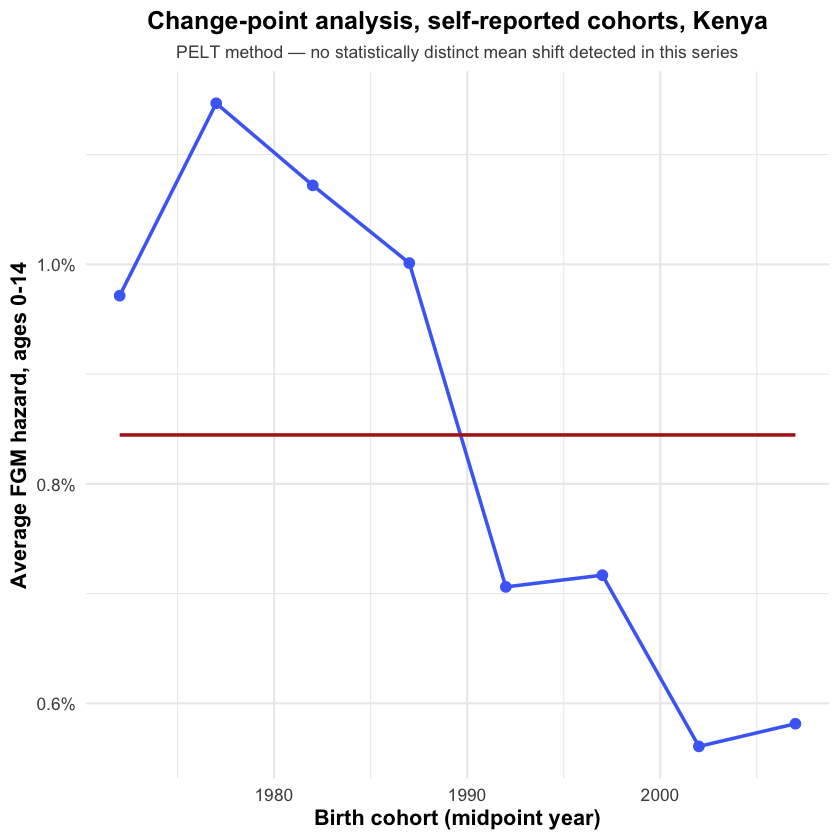

In [31]:
if (run_change_point) {
  library(changepoint)

  # Average over childhood ages 0-14 only (Lexis bands 0-4, 5-9, 10-14), and
  # keep only cohorts observed in all three bands, so every point averages the
  # same ages. Adult bands have near-zero hazard and older cohorts have more
  # of them, so including them would drag older cohorts' averages down.
  childhood_band_mids <- c(2.5, 7.5, 12.5)
  cohort_series <- lexis_grid_self |>
    dplyr::filter(age_band_mid %in% childhood_band_mids, !is.na(hazard)) |>
    dplyr::group_by(cohort_mid) |>
    dplyr::summarise(n_bands = dplyr::n(), mean_hazard = mean(hazard), .groups = "drop") |>
    dplyr::filter(n_bands == length(childhood_band_mids)) |>
    dplyr::arrange(cohort_mid)
  print(cohort_series)

  cpt_result <- changepoint::cpt.mean(cohort_series$mean_hazard, method = "PELT")
  n_segments <- length(cpt_result@cpts)

  change_point_estimate <- tibble::tibble(
    country = country_name,
    basis = "self-reported cohorts, mean hazard over ages 0-14",
    changepoint_detected = n_segments > 1,
    estimated_change_cohort = if (n_segments > 1) cohort_series$cohort_mid[cpt_result@cpts[1]] else NA_real_
  )
  readr::write_csv(change_point_estimate, file.path(output_dir, paste0(country_iso3, "_change_point.csv")))
  print(change_point_estimate)

  segment_bounds <- c(0, cpt_result@cpts)
  cohort_series_plot <- cohort_series |>
    dplyr::mutate(index = dplyr::row_number(),
                   segment = cut(index, breaks = segment_bounds, labels = FALSE)) |>
    dplyr::group_by(segment) |>
    dplyr::mutate(segment_mean = mean(mean_hazard)) |>
    dplyr::ungroup()

  subtitle_text <- if (n_segments > 1) {
    paste("PELT method \u2014 detected shift after the",
          cohort_series_plot$cohort_mid[cpt_result@cpts[1]], "cohort (red line: segment means)")
  } else {
    "PELT method \u2014 no statistically distinct mean shift detected in this series"
  }

  cpt_plot <- ggplot2::ggplot(cohort_series_plot, ggplot2::aes(x = cohort_mid, y = mean_hazard)) +
    ggplot2::geom_line(color = "#4C6EF5", linewidth = 1) +
    ggplot2::geom_point(size = 2.5, color = "#4C6EF5") +
    ggplot2::geom_line(ggplot2::aes(y = segment_mean, group = segment), color = "firebrick", linewidth = 1) +
    ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 0.1)) +
    ggplot2::labs(
      title = paste("Change-point analysis, self-reported cohorts,", country_name),
      subtitle = subtitle_text,
      x = "Birth cohort (midpoint year)", y = "Average FGM hazard, ages 0-14"
    ) +
    ggplot2::theme_minimal(base_size = 13) +
    ggplot2::theme(
      plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
      plot.subtitle = ggplot2::element_text(size = 10.5, hjust = 0.5, color = "grey30"),
      axis.title = ggplot2::element_text(face = "bold")
    )

  print(cpt_plot)
  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_change_point.png")),
                   plot = cpt_plot, width = 8, height = 5, dpi = 300, bg = "white")
} else {
  message("Change point analysis disabled for this run")
}


## 15. Model validation

Compare the Kaplan Meier baseline, the discrete time hazard model, and the spatial small area model on a common set of ages or regions, and check sensitivity to DHS versus MICS survey type and to sparse area sample sizes, following section 2.5 and the validation checks referenced throughout the improved methodology document.

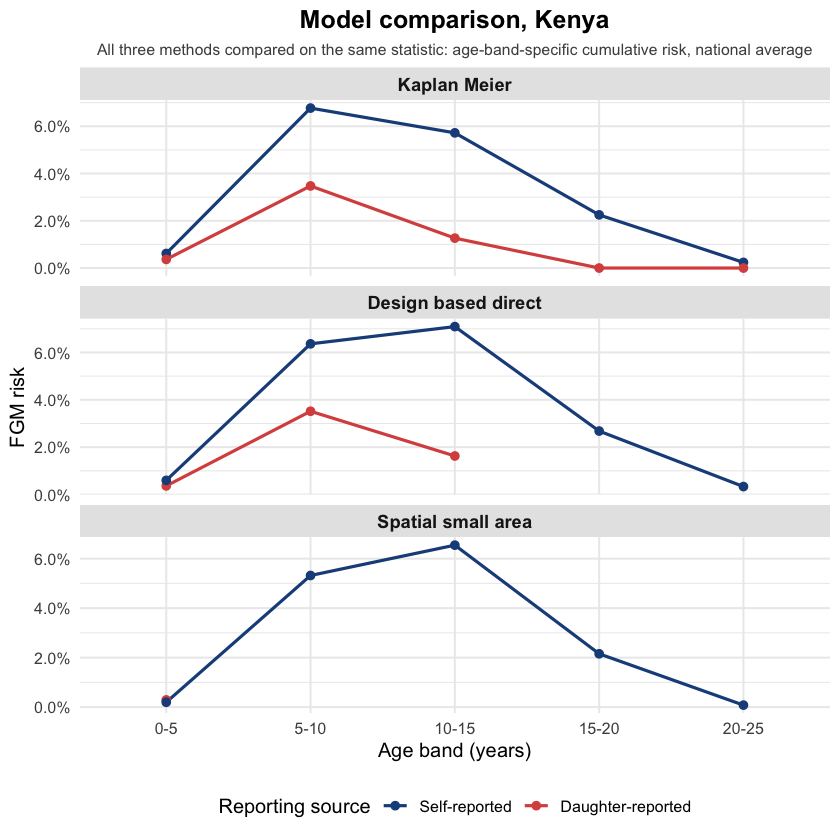

In [32]:
surv_at_t_simple <- function(km_fit, t) {
  if (t <= 0) return(1)
  before <- which(km_fit$time <= t)
  if (length(before) == 0) return(1)
  km_fit$surv[max(before)]
}

national_km_age_band_risk <- function(record_data, record_label) {
  design <- survey::svydesign(ids = ~cluster, strata = ~interaction(survey_year, region), weights = ~weight, data = record_data, nest = TRUE)
  # se=TRUE omitted here -- it exhausts memory at national scale, and isn't
  # needed for a visual model-comparison chart (point estimates only)
  fit_r <- survey::svykm(survival::Surv(time, fgm_event) ~ 1, design = design)
  s <- sapply(age_band_cutpoints, function(t) surv_at_t_simple(fit_r, t))
  purrr::map_dfr(seq_along(age_band_cutpoints)[-length(age_band_cutpoints)], function(i) {
    tibble::tibble(age_band = age_band_levels[i], fgm_risk = 1 - (s[i + 1] / s[i]))
  }) |> dplyr::mutate(record_type = record_label, model = "Kaplan Meier")
}

km_national <- dplyr::bind_rows(
  national_km_age_band_risk(fgm_events |> dplyr::filter(record_type == "self"), "self"),
  national_km_age_band_risk(fgm_events |> dplyr::filter(record_type == "daughter"), "daughter")
)

# NOTE: these used to reference age_band_self/age_band_daughter, which are
# never created anywhere in this notebook -- full_risk_self/full_risk_daughter
# (built in the direct-estimates cell) are the correct, actually-existing objects.
direct_national <- dplyr::bind_rows(full_risk_self, full_risk_daughter) |>
  dplyr::group_by(age_band, record_type) |>
  dplyr::summarise(fgm_risk = weighted.mean(event, w = sum_weight, na.rm = TRUE), .groups = "drop") |>
  dplyr::mutate(model = "Design based direct")

spatial_national <- dplyr::bind_rows(smoothed_by_band_self, smoothed_by_band_daughter) |>
  dplyr::group_by(age_band, record_type) |>
  dplyr::summarise(fgm_risk = weighted.mean(smoothed_risk, w = sum_weight, na.rm = TRUE), .groups = "drop") |>
  dplyr::mutate(model = "Spatial small area")

validation_comparison <- dplyr::bind_rows(km_national, direct_national, spatial_national) |>
  dplyr::mutate(
    age_band = factor(age_band, levels = age_band_levels),
    model = factor(model, levels = c("Kaplan Meier", "Design based direct", "Spatial small area")),
    record_type = factor(record_type, levels = c("self", "daughter"), labels = c("Self-reported", "Daughter-reported"))
  )

validation_plot <- ggplot2::ggplot(validation_comparison, ggplot2::aes(
    x = age_band, y = fgm_risk, color = record_type, group = record_type)) +
  ggplot2::geom_line(linewidth = 0.9, na.rm = TRUE) +
  ggplot2::geom_point(size = 2, na.rm = TRUE) +
  ggplot2::facet_wrap(~model, scales = "free_y", ncol = 1) +
  ggplot2::scale_color_manual(values = c("Self-reported" = "#1D4E89", "Daughter-reported" = "#D9534F")) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 0.1)) +
  ggplot2::labs(
    title = paste("Model comparison,", country_name),
    subtitle = "All three methods compared on the same statistic: age-band-specific cumulative risk, national average",
    y = "FGM risk", x = "Age band (years)", color = "Reporting source"
  ) +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(
    plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
    plot.subtitle = ggplot2::element_text(size = 9.5, hjust = 0.5, color = "grey30"),
    strip.text = ggplot2::element_text(face = "bold", size = 11),
    strip.background = ggplot2::element_rect(fill = "grey90", color = NA),
    legend.position = "bottom"
  )

print(validation_plot)

ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_model_validation.png")),
                 plot = validation_plot, width = 9, height = 11, dpi = 300, bg = "white")

readr::write_csv(validation_comparison, file.path(output_dir, paste0(country_iso3, "_model_validation.csv")))


## 16. Optional machine learning cross check

A random survival forest as a covariate screening and cross check layer, not a replacement for the core survival or small area model, following section 2.5 of the improved methodology document.

In [33]:
if (run_ml_crosscheck) {
  library(randomForestSRC)

  # randomForestSRC::rfsrc() refuses character predictors outright ("please convert all
  # characters to factors"), a pre-existing gap in the original code surfaced now that
  # this cell actually runs, urban_rural/region/survey_type/ethnicity/record_type/
  # birth_cohort come out of 00_EDA_DHS_Country_Year.ipynb as character (birth_cohort is
  # already a factor).
  rsf_data <- fgm_events |>
    dplyr::select(time, fgm_event, urban_rural, region, survey_type, ethnicity, record_type, birth_cohort) |>
    tidyr::drop_na() |>
    dplyr::mutate(dplyr::across(dplyr::where(is.character), as.factor))

  rsf_survey_type_term <- if (dplyr::n_distinct(rsf_data$survey_type) > 1) " + survey_type" else ""
  rsf_record_type_term  <- if (dplyr::n_distinct(rsf_data$record_type) > 1) " + record_type" else ""

  rsf_model <- randomForestSRC::rfsrc(
    as.formula(paste0("Surv(time, fgm_event) ~ urban_rural + region + ethnicity + birth_cohort",
                       rsf_survey_type_term, rsf_record_type_term)),
    data = rsf_data, ntree = 500, importance = TRUE
  )

  print(rsf_model)
  randomForestSRC::vimp(rsf_model)$importance
} else {
  message("Machine learning cross check disabled for this run")
}


 randomForestSRC 3.7.0 
 
 Type rfsrc.news() to see new features, changes, and bug fixes. 
 





Attaching package: ‘randomForestSRC’




The following object is masked from ‘package:purrr’:

    partial




                         Sample size: 31361
                    Number of deaths: 4885
                     Number of trees: 500
           Forest terminal node size: 15
       Average no. of terminal nodes: 557.724
No. of variables tried at each split: 3
              Total no. of variables: 5
       Resampling used to grow trees: swor
    Resample size used to grow trees: 19820
                            Analysis: RSF
                              Family: surv
                      Splitting rule: logrank *random*
       Number of random split points: 10
                          (OOB) CRPS: 1.95824314
             (OOB) standardized CRPS: 0.0559498
   (OOB) Requested performance error: 0.08287853



urban_rural       region    ethnicity birth_cohort  record_type 
  0.02021183   0.12338664   0.51563941   0.03840847   0.08691370

## 17. Final outputs

Collect every table and figure produced above into one output folder for this country, ready to feed into a cross country 18 country summary report.

In [34]:
cat("All outputs for", country_name, "written to:", output_dir, "\n")
list.files(output_dir, recursive = TRUE)

All outputs for Kenya written to: ../03_Outputs/KEN 


[1] "Attitude_v3/KEN_attitude_association_matrix_v3.csv"                            
 [2] "Attitude_v3/KEN_attitude_association_matrix_v3.png"                            
 [3] "Attitude_v3/KEN_attitude_covariate_adjusted_by_state_v3.csv"                   
 [4] "Attitude_v3/KEN_attitude_covariate_adjusted_map_v3.png"                        
 [5] "Attitude_v3/KEN_attitude_direct_by_state_v3.csv"                               
 [6] "Attitude_v3/KEN_attitude_direct_national_v3.csv"                               
 [7] "Attitude_v3/KEN_attitude_feature_importance_v3.csv"                            
 [8] "Attitude_v3/KEN_attitude_fixed_effects_v3.csv"                                 
 [9] "Attitude_v3/KEN_attitude_model_fit_v3.csv"                                     
[10] "Attitude_v3/KEN_attitude_national_comparison_v3.csv"                           
[11] "Attitude_v3/KEN_attitude_residual_map_v3.png"                                  
[12] "Attitude_v3/KEN_attitude_residual_spatial_effect_v3.csv"                       
[13] "Attitude_v3/KEN_attitude_selected_predictors_v3.csv"                           
[14] "Attitude_v3/KEN_attitude_selected_predictors_v3.rds"                           
[15] "Attitude_v3/KEN_attitude_validation_comparison_v3.csv"                         
[16] "Attitude_v3/KEN_attitude_validation_metrics_v3.csv"                            
[17] "Attitude_v3/KEN_attitude_validation_v3.png"                                    
[18] "Attitude_v3/KEN_attitude_vif_v3.csv"                                           
[19] "FGM_Prevalence/KEN_prevalence_association_matrix.csv"                          
[20] "FGM_Prevalence/KEN_prevalence_association_matrix.png"                          
[21] "FGM_Prevalence/KEN_prevalence_covariate_adjusted_by_cohort_daughter.csv"       
[22] "FGM_Prevalence/KEN_prevalence_covariate_adjusted_by_cohort_self.csv"           
[23] "FGM_Prevalence/KEN_prevalence_covariate_adjusted_daughter.csv"                 
[24] "FGM_Prevalence/KEN_prevalence_covariate_adjusted_map_by_cohort_daughter.png"   
[25] "FGM_Prevalence/KEN_prevalence_covariate_adjusted_map_by_cohort_self.png"       
[26] "FGM_Prevalence/KEN_prevalence_covariate_adjusted_map_daughter.png"             
[27] "FGM_Prevalence/KEN_prevalence_covariate_adjusted_map_self.png"                 
[28] "FGM_Prevalence/KEN_prevalence_covariate_adjusted_national_average.csv"         
[29] "FGM_Prevalence/KEN_prevalence_covariate_adjusted_self.csv"                     
[30] "FGM_Prevalence/KEN_prevalence_direct_daughter.csv"                             
[31] "FGM_Prevalence/KEN_prevalence_direct_self.csv"                                 
[32] "FGM_Prevalence/KEN_prevalence_feature_importance.csv"                          
[33] "FGM_Prevalence/KEN_prevalence_map_daughter.png"                                
[34] "FGM_Prevalence/KEN_prevalence_map_self.png"                                    
[35] "FGM_Prevalence/KEN_prevalence_predictor_association_ranking.csv"               
[36] "FGM_Prevalence/KEN_prevalence_residual_map_daughter.png"                       
[37] "FGM_Prevalence/KEN_prevalence_residual_map_self.png"                           
[38] "FGM_Prevalence/KEN_prevalence_residual_spatial_daughter.csv"                   
[39] "FGM_Prevalence/KEN_prevalence_residual_spatial_self.csv"                       
[40] "FGM_Prevalence/KEN_prevalence_smoothed_daughter.csv"                           
[41] "FGM_Prevalence/KEN_prevalence_smoothed_self.csv"                               
[42] "FGM_Prevalence/KEN_prevalence_trend_by_year.png"                               
[43] "FGM_Prevalence/KEN_prevalence_trend_covariate_adjusted_annotated.png"          
[44] "KEN_change_point.csv"                                                          
[45] "KEN_change_point.png"                                                          
[46] "KEN_cohort_age_band_risk_daughter.csv"                                         
[47] "KEN_cohort_age_band_risk_self.csv"     